# What can BCA do for policy optimization? Four toy experiments in one notebook

BCA (Bayesian Conformal Aggregation) is this repository's calibration method. It turns held-out errors into a threshold that holds with a stated confidence. This notebook brings together four toy experiments that ask where, if anywhere, that threshold helps a policy choose better actions.

## Bottom line

- **As extra caution inside training, BCA did not help.** The hosts use BCA as a **width**: a margin of error subtracted from the critic's values. In Parts 1 and 2, the width was calibrated where it was measured, but it improved no decision and cost return. In Part 2, the two width rules had regret 0.43 and 0.38, against 0.12 for simply refusing actions the training data barely cover.
- **As a gate on a risky action, BCA did help.** A **gate** reads held-out outcomes of the risky action and lets the action through only if they pass. In Part 2, every gate that read those outcomes closed 38% to 87% of the distance between the best simple rule and perfect choices. With the outcomes shuffled, the gain disappeared.
- **BCA's tail gate keeps a safety promise for the data in hand.** It let an unsafe action through in at most 3% of seeds in any world. Split conformal prediction, whose promise holds only on average, did so in up to 38%. With equal weights, though, BCA is a textbook test: it matched the exact binomial test in 99.6% of cases, and it cannot say yes with fewer than 29 tries.
- **BCA's mean gate earns the most at equal safety.** Held to at most 5% harmful acceptances in every world, it earned 0.084 per situation. That is about twice the next-best gate (0.040) and 4.5 times the best gate not built from BCA (0.019). Without a safety requirement, the plain held-out average earns more (0.158 against 0.045).
- **BCA's weights keep its promise when deployment visits different states than the log.** Ignoring the shift, the tail gate let unsafe actions through in up to 90% of seeds; with weights, in at most 4.3%. The weights also used the evidence better than the simple valid alternatives. The price is evidence: under a strong shift, the gate needs about 83 tries before it can say yes at all, against 29 with no shift.
- **The role we recommend for BCA is a certificate on each deviation, not a training penalty.** Compare held-out outcomes of the deviation with the fallback action's value. Use the mean gate for return at a fixed safety level, and the tail gate for "rarely worse than the fallback". Use weights only when the states differ.

| Part | Question | Answer |
|---|---|---|
| 1 | Does BCA's width, used as extra caution, make the policy choose better? | No. It is calibrated where the log has data, but changes no decision for the better. |
| 2 | Is there any way BCA can change a decision for the better? | Yes: as a gate that reads held-out outcomes of the risky action. Its tail gate was the safest gate. |
| 3 | Can a BCA gate also raise return? | Its mean gate earns the most when every gate must be equally safe, but not when safety is ignored. |
| 4 | Do BCA's weights help when the log and deployment visit different states? | Yes. They keep the promise where ignoring the shift breaks it, at a cost in evidence. |

## How to use this notebook

**How to run.** Open it in the repository's `.venv` and choose Run All. It needs Python 3, NumPy and Matplotlib, and takes about four to six minutes, almost all of it in Part 4. Nothing is downloaded. One optional check in Part 4 compares with the repository's `calibration/wbcp.py`, and skips itself if that file is missing.

**How it is laid out.** There are four parts, one per experiment, in the order they were run. Each part gives the question, the setup and the claims, then the code with its results, then what it found. The code cells are marked to start collapsed, in editors that support it; expand any of them to read the code. Each part defines everything it uses, so any part can be rerun from its first code cell.

**How far to trust it.**
- Everything is a toy, run on toy seeds only. Nothing here is evidence about ThrusterChain or the hosts.
- Part 1 is an exploratory demo on one seed, with no claims.
- Parts 2 to 4 were pre-registered. Each claim's **kill rule** (the result that would shelve it) was written down and fingerprinted (SHA-256) before the experiment's first run. Each part prints its fingerprint, which must match the one recorded then. The rules say "this notebook" because each experiment first ran in a notebook of its own.
- Each part's code is copied unchanged from its experiment's own notebook, and rerunning it here reproduces every printed result exactly. Only the explanations are new.

## Words used

- **Policy:** the rule that picks an action in each state. **Critic:** the learned estimate of each action's value.
- **Safe action**, or **fallback:** an action the log covers well, so its value is known.
- **Risky action**, or **deviation:** an action the policy wants but the log barely covers. Think of full throttle where the log rarely went. Parts 1 and 2 call it **venture**, and Part 3 calls it a **candidate**.
- **Held-out tries:** logged outcomes of the risky action that training never saw. Only the gates read them. Part 2 calls them **survivors**.
- **Gate:** a rule that reads the held-out tries and either lets the risky action through or falls back.
- **Promise:** what a gate guarantees, with 95% confidence.
  - **Tail promise:** at most 10% of the risky action's outcomes fall below the fallback.
  - **Mean promise:** the risky action's average gain over the fallback is above 0.
- **Unsafe world:** more than 10% of the risky action's outcomes fall below the fallback. **Harmful world:** its average gain over the fallback is below 0. A gate that keeps its promise lets the risky action through in at most about 5% of seeds in such worlds.
- **Regret:** return lost against perfect choices; 0 is perfect. **Gain:** return won over always falling back; 0 is no better.
- **Kill rule:** a result, written down before the run, that would shelve a claim. **Alive** means the claim survived its kill rule; **shelved** means it did not.
- **How BCA works, in one paragraph.** BCA gives each held-out score a random weight, plus one extra weight for an unseen worst case. It finds the score where 90% of the total weight is crossed. It repeats this 1,000 times and reports a value it is 95% sure of. **With weights** (Parts 1 and 4), each try's random weight is first multiplied by (how often deployment visits that try's state) ÷ (how often the log did).

---
# Part 1. Does BCA's width make the policy choose better?

*An exploratory demo on one seed, with no claims. Original notebook: `bca_discrete_toy.ipynb`.*

**The question.** The hosts use BCA as a width: a calibrated margin of error on the critic's values, subtracted from them as extra caution. Does that width make the policy choose better?

**The world.** There are two steps (t = 0, 1) and two contexts (c = 0, 1). At each step the policy picks **safe** (action 0) or **venture** (action 1).

| t | context | safe pays | venture pays |
|---|---|---|---|
| 0 | 0 | 0.1 | 0.3 |
| 0 | 1 | 0.1 | −0.5 or 1.1, half each |
| 1 | 0 | 1 | 0 or 3, half each (average 1.5) |
| 1 | 1 | 1 | never tried in the log. "Harmful" world: −5 (80% of the time) or 2. "Harmless" world: 2 |

- The log never ventures at t = 1 in context 1, so both worlds produce exactly the same data. No rule can tell them apart.
- The critic is each cell's training average. The never-tried cell keeps an optimistic guess of 2.5.
- Context 1 is rare in the log (15%) but common at test time (65%). The **weighted** methods correct for that known shift.
- A method's **width** is its calibrated threshold times a scale that shrinks as training rows grow (1 ÷ √count). The policy picks the action with the best value minus width.
- Every method except "no penalty" refuses actions with no training data. **Support only** does just that. **Scale only** also subtracts the count scale, with no calibration.

**Three questions, kept apart.** Does the width cover the outcomes it was calibrated on? Does it contain the true values? Does the policy do better? Only the last one is policy optimization.

**How to read the outputs.**
- The first output lists training counts and critic values per [time, context, action], then the count scales.
- The second lists each method's threshold at each step.
- The third has, in order:
  - **Coverage at test time.** Read the "exact" column at step 0, against a 90% target.
  - **A control with no shift.**
  - **A novelty probe:** every method refuses the never-tried action.
  - **For each world:** the true values, how often BCA's intervals contain them, and the **policy table**. It gives return, regret, failure risk, and the chosen actions as [[t=0: context 0, context 1], [t=1: context 0, context 1]], where 1 is venture.
- The bar chart repeats the policy tables.

In [1]:
import time, math, itertools
import numpy as np
import matplotlib.pyplot as plt
START = time.perf_counter()
SEED = 7                      # demo seed (already seen); see the note above
N_TRAIN, N_CAL, N_TEST = 600, 300, 2000
DRAWS = 1000
ALPHA, BETA = 0.1, 0.95
P_CAL = np.array([0.85, 0.15])
P_TEST = np.array([0.35, 0.65])
UNKNOWN_PRIOR = 2.5
SCALE_FLOOR = 0.02
PENALTY_GAIN = 1.0
RUN_SWEEP = False
N_SWEEP = 200                 # seeds in the optional sweep (cell 14)
# Independent SeedSequence children: never split transitions from the same episode.
streams = [np.random.default_rng(s) for s in np.random.SeedSequence(SEED).spawn(6)]
train_rng, cal_rng, test_rng, novel_rng, boot_rng, spare_rng = streams
assert 0 < ALPHA < 1 and 0 < BETA < 1, "ALPHA and BETA must lie strictly between 0 and 1"
assert np.all(P_CAL > 0) and np.all(P_TEST > 0), \
    "P_CAL and P_TEST must be > 0 for every context (finite likelihood ratio)"
assert np.isclose(P_CAL.sum(), 1) and np.isclose(P_TEST.sum(), 1), "P_CAL and P_TEST must each sum to 1"

In [2]:
def outcomes(t, c, a, variant="harmful"):
    # Simulator/oracle only. Learner receives sampled (c,a,r), not this table.
    if t == 0:
        if a == 0: return [(1., .1)]
        return [(1., .3)] if c == 0 else [(.5, -.5), (.5, 1.1)]
    if a == 0: return [(1., 1.)]
    if c == 0: return [(.5, 0.), (.5, 3.)]
    return [(.8, -5.), (.2, 2.)] if variant == "harmful" else [(1., 2.)]

# Behavior policy: probability of the venture (action 1) at [stage t, context c].
P_VENTURE = np.array([[.5, .5], [.25, 0.]])

def episodes(n, p, rng, variant="harmful", novel=False):
    c = rng.choice(2, n, p=p)
    a = np.zeros((n, 2), dtype=int)
    for t in range(2):
        a[:, t] = rng.binomial(1, P_VENTURE[t, c])
    if novel:
        c[:] = 1
        a[:, 1] = 1
    r = np.zeros((n, 2))
    for i in range(n):
        for t in range(2):
            o = outcomes(t, int(c[i]), int(a[i,t]), variant)
            k = rng.choice(len(o), p=[x[0] for x in o])
            r[i,t] = o[k][1]
    return {"c": c, "a": a, "r": r}

train = episodes(N_TRAIN, P_CAL, train_rng)
cal = episodes(N_CAL, P_CAL, cal_rng)
test = episodes(N_TEST, P_TEST, test_rng)
novel = episodes(N_TEST, P_TEST, novel_rng, novel=True)

def fit_tabular(data):
    q = np.full((2,2,2), UNKNOWN_PRIOR, dtype=float)
    counts = np.zeros((2,2,2), dtype=int)
    # Fixed continuation policy pi0(c)=safe at stage 1.
    # Fit terminal means then frozen bootstrapped stage-0 targets on training only.
    for t in (1,0):
        for c in range(2):
            for a in range(2):
                mask = (data["c"] == c) & (data["a"][:,t] == a)
                counts[t,c,a] = mask.sum()
                if mask.any():
                    y = data["r"][mask,t].copy()
                    if t == 0: y += q[1,c,0]
                    q[t,c,a] = y.mean()
    # Sparse cells have a larger heuristic scale. This is NOT an estimated SE.
    scale = np.maximum(SCALE_FLOOR, 1 / np.sqrt(np.maximum(counts, 1)))
    return q, counts, scale

q, counts, scale = fit_tabular(train)
supported = counts > 0
print("Training counts [time, context, action]:\n", counts)
print("Frozen critic:\n", q)
print("Train-only count scales:\n", scale)

def targets(data, t):
    y = data["r"][:,t].copy()
    if t == 0: y += q[1,data["c"],0]
    return y

# Cells with a certain outcome should have residual exactly 0, but the fitted mean of
# identical rewards can be off by about 1e-16. Snap such floating-point dust to 0.
RESID_TOL = 1e-9
def snap(r):
    return np.where(r < RESID_TOL, 0., r)

def residual(data, t):
    c, a = data["c"], data["a"][:,t]
    return snap(np.abs(targets(data,t) - q[t,c,a]))

def scores(data, t):
    c, a = data["c"], data["a"][:,t]
    bad = ~supported[t,c,a]
    if bad.any():
        missing = sorted({(t,int(ci),int(ai)) for ci,ai in zip(c[bad],a[bad])})
        raise ValueError(f"Calibration cells {missing} [t,c,a] have no training data; "
                         "increase N_TRAIN or change SEED (refusing to certify unseen cells).")
    return residual(data,t) / scale[t,c,a]

cal_scores = [scores(cal,t) for t in range(2)]

Training counts [time, context, action]:
 [[[263 240]
  [ 53  44]]

 [[396 107]
  [ 97   0]]]
Frozen critic:
 [[[1.1        1.3       ]
  [1.1        1.44545455]]

 [[1.         1.62616822]
  [1.         2.5       ]]]
Train-only count scales:
 [[[0.06166264 0.06454972]
  [0.13736056 0.15075567]]

 [[0.05025189 0.09667365]
  [0.10153462 1.        ]]]


In [3]:
def weighted_quantile(s, w, level, extra=0.):
    s, w = np.asarray(s), np.asarray(w)
    order = np.argsort(s, kind="stable")
    s, w = s[order], w[order]
    target = level * (w.sum() + extra)
    k = np.searchsorted(np.cumsum(w), target, side="left")
    return float(s[k]) if k < len(s) else np.inf

def bca_threshold(s, rng, weights=None, test_mass=1., draws=DRAWS):
    s = np.asarray(s, float)
    w = np.ones(len(s)) if weights is None else np.asarray(weights, float)
    assert len(s) and np.all(np.isfinite(s))
    assert np.all(np.isfinite(w)) and np.all(w > 0) and test_mass > 0
    order = np.argsort(s, kind="stable")
    s, w = s[order], w[order]
    empirical = weighted_quantile(s, w, 1-ALPHA)
    crossings = []
    # Small bounded batches.
    for start in range(0, draws, 128):
        e = rng.exponential(size=(min(128,draws-start),len(s)+1))
        mass = e[:,:-1] * w
        total = mass.sum(axis=1) + test_mass * e[:,-1]
        hit = np.cumsum(mass,axis=1) >= (1-ALPHA)*total[:,None]
        crossings.extend(np.where(hit.any(axis=1), s[hit.argmax(axis=1)], np.inf))
    crossings = np.sort(crossings)
    credible = float(crossings[math.ceil(BETA*draws)-1])
    return max(empirical,credible), empirical, credible

ratio = P_TEST / P_CAL
wbar = float(P_TEST @ ratio)
cal_weights = ratio[cal["c"]]
thresholds = {name:np.zeros((2,2)) for name in
              ("empirical", "conformal", "BCA", "weighted empirical",
               "weighted conformal", "weighted BCA")}
details = []
for t,s in enumerate(cal_scores):
    b, e, cr = bca_threshold(s, boot_rng)
    wb, we, wcr = bca_threshold(s, boot_rng, cal_weights, wbar)
    for c in range(2):
        thresholds["empirical"][t,c] = e
        thresholds["BCA"][t,c] = b
        thresholds["weighted empirical"][t,c] = we
        thresholds["weighted BCA"][t,c] = wb
        thresholds["conformal"][t,c] = weighted_quantile(s,np.ones(len(s)),1-ALPHA,1.)
        thresholds["weighted conformal"][t,c] = weighted_quantile(s,cal_weights,1-ALPHA,ratio[c])
    details.append((t,e,cr,b,we,wcr,wb))
print("Known context ratios:", ratio, "  E_test[w] =", wbar)
print("stage, empirical, credible, BCA, weighted empirical, weighted credible, weighted BCA")
for row in details: print(tuple(round(x,4) for x in row))

def widths(name):
    out = thresholds[name][:,:,None] * scale
    return np.where(supported, out, np.inf)

Known context ratios: [0.41176471 4.33333333]   E_test[w] = 2.960784313725491
stage, empirical, credible, BCA, weighted empirical, weighted credible, weighted BCA
(0, 0.0, 0.0, 0.0, 4.3418, 6.2714, 6.2714)
(1, 16.8212, 16.8212, 16.8212, 14.211, 14.211, 14.211)


In [4]:
def coverage_report(data, name, t):
    c,a = data["c"],data["a"][:,t]
    h = widths(name)[t,c,a]
    finite = np.isfinite(h)
    # Compare in score space, the quantity the threshold was selected on.
    covered = residual(data,t) / scale[t,c,a] <= thresholds[name][t,c]
    cov = covered[finite].mean() if finite.any() else np.nan
    width = (2*h[finite]).mean() if finite.any() else np.nan
    return cov, 1-finite.mean(), width

def exact_coverage(name, t, p=P_TEST, variant="harmful"):
    # The same three numbers as coverage_report, computed exactly from the outcome
    # table, the behavior probabilities P_VENTURE and the context law p. No sampling.
    h = widths(name)
    finite_mass = covered_mass = width_mass = 0.
    for c in range(2):
        for a in range(2):
            mass = p[c] * (P_VENTURE[t,c] if a == 1 else 1 - P_VENTURE[t,c])
            if mass == 0 or not np.isfinite(h[t,c,a]):
                continue
            finite_mass += mass
            width_mass += mass * 2 * h[t,c,a]
            for prob, r in outcomes(t, c, a, variant):
                y = r + q[1,c,0] if t == 0 else r
                score = snap(np.abs(y - q[t,c,a])) / scale[t,c,a]
                covered_mass += mass * prob * (score <= thresholds[name][t,c])
    if finite_mass == 0:
        return np.nan, 1., np.nan
    return covered_mass / finite_mass, 1 - finite_mass, width_mass / finite_mass

print("Supported shifted test: method | stage | finite coverage: sampled, exact | refusal | mean finite full width")
for name in thresholds:
    for t in range(2):
        cv,rf,wi = coverage_report(test,name,t)
        print(f"{name:20} {t}  {cv:.3f}  {exact_coverage(name,t)[0]:.4f}  {rf:.3f}  {wi:.3f}")
print("\nNo-shift control, exact (contexts from P_CAL): method | stage 0 | stage 1")
for name in ("empirical","conformal","BCA"):
    print(f"{name:20} {exact_coverage(name,0,P_CAL)[0]:.4f}  {exact_coverage(name,1,P_CAL)[0]:.4f}")
print("\nNovelty probe, terminal stage (NaN means no finite certificate):")
for name in ("conformal","BCA","weighted conformal","weighted BCA"):
    cv,rf,wi = coverage_report(novel,name,1)
    print(f"{name:20} refusal={rf:.3f}  finite coverage={cv}  width={wi}")

# ORACLE: exact dynamic programming. Only diagnostics below use outcomes().
def oracle_q(variant, continuation=None):
    oq = np.zeros((2,2,2))
    for t in (1,0):
        for c in range(2):
            for a in range(2):
                oq[t,c,a] = sum(p*r for p,r in outcomes(t,c,a,variant))
                if t == 0:
                    oq[t,c,a] += (oq[1,c].max() if continuation is None
                                     else oq[1,c,continuation[c]])
    return oq

def exact_evaluate(policy, variant, p=P_TEST):
    value = np.zeros((2,2))
    failure = np.zeros(2)
    for c in range(2):
        a1 = int(policy[1,c])
        value[1,c] = sum(prob*r for prob,r in outcomes(1,c,a1,variant))
        failure[c] = sum(prob for prob,r in outcomes(1,c,a1,variant) if r < 0)
        value[0,c] = sum(prob*r for prob,r in outcomes(0,c,int(policy[0,c]),variant)) + value[1,c]
    ret = float(p @ value[0])
    optimum = float(p @ oracle_q(variant)[0].max(axis=-1))
    return ret, optimum-ret, float(p @ failure)

def make_policy(name):
    if name == "no penalty":
        utility = q.copy()
    elif name == "support only":
        utility = np.where(supported,q,-np.inf)
    elif name == "scale only":
        utility = np.where(supported,q-PENALTY_GAIN*scale,-np.inf)
    else:
        h = widths(name)
        utility = np.where(np.isfinite(h),q-PENALTY_GAIN*h,-np.inf)
    refused = ~np.isfinite(utility).any(axis=-1)
    # A tie: both actions finite and within RESID_TOL (floating-point dust counts as equal).
    ties = np.isfinite(utility).all(axis=-1) & np.isclose(utility[...,0], utility[...,1], rtol=0, atol=RESID_TOL)
    policy = utility.argmax(axis=-1)
    # SAME fallback: safe action 0 when every candidate is refused. Ties also go to 0.
    policy[refused | ties] = 0
    return policy,refused,ties

methods = ["no penalty","support only","scale only","conformal","BCA",
           "weighted conformal","weighted BCA"]
results = {}
for variant in ("harmful","harmless"):
    print("\nORACLE world:",variant)
    trueq = oracle_q(variant, continuation=np.zeros(2,dtype=int))
    print("True Q^safe:\n",trueq)
    for name in ("BCA","weighted BCA"):
        h = widths(name); finite = np.isfinite(h)
        contained = snap(np.abs(q-trueq)) / scale <= thresholds[name][:,:,None]   # score space
        print(name, "finite-cell Q^safe containment =",
              np.mean(contained[finite]),
              "finite-cell mean abs Q error =", np.mean(np.abs(q-trueq)[finite]))
    print("method | return | regret | failure risk | actions [t,c] | fallback states")
    results[variant] = []
    for name in methods:
        pi, fallback, ties = make_policy(name)
        metrics = exact_evaluate(pi,variant)
        results[variant].append(metrics)
        line = f"{name:20} {metrics[0]:7.3f} {metrics[1]:7.3f} {metrics[2]:7.3f} {pi.tolist()} {int(fallback.sum())}"
        if ties.any():
            line += f"  TIE at [t,c] {np.argwhere(ties).tolist()}, taken as safe"
        print(line)

Supported shifted test: method | stage | finite coverage: sampled, exact | refusal | mean finite full width
empirical            0  0.674  0.6750  0.000  0.000
empirical            1  1.000  1.0000  0.000  2.949
conformal            0  0.674  0.6750  0.000  0.000
conformal            1  1.000  1.0000  0.000  2.949
BCA                  0  0.674  0.6750  0.000  0.000
BCA                  1  1.000  1.0000  0.000  2.949
weighted empirical   0  0.842  0.8375  0.000  1.005
weighted empirical   1  0.955  0.9563  0.000  2.492
weighted conformal   0  0.842  0.8375  0.000  1.005
weighted conformal   1  0.955  0.9563  0.000  2.492
weighted BCA         0  1.000  1.0000  0.000  1.451
weighted BCA         1  0.955  0.9563  0.000  2.492

No-shift control, exact (contexts from P_CAL): method | stage 0 | stage 1
empirical            0.9250  1.0000
conformal            0.9250  1.0000
BCA                  0.9250  1.0000

Novelty probe, terminal stage (NaN means no finite certificate):
conformal          

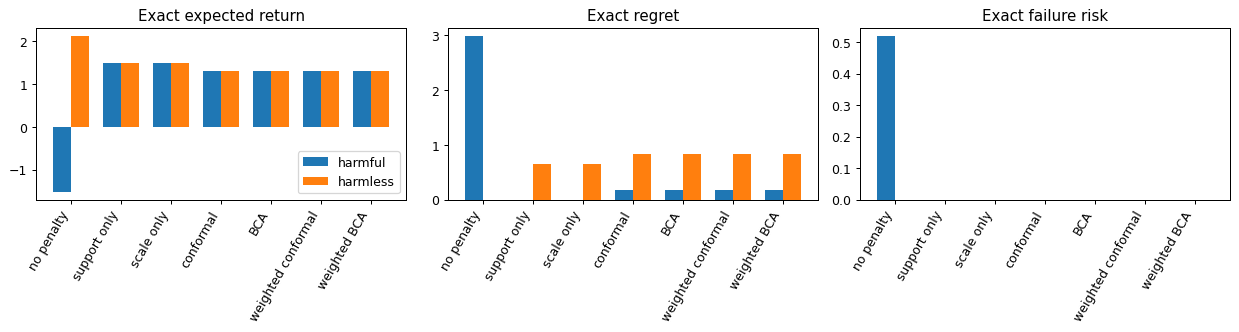

In [5]:
fig, axes = plt.subplots(1,3,figsize=(14,3.8))
x = np.arange(len(methods))
for k, (metric,title) in enumerate(zip(range(3),("Exact expected return","Exact regret","Exact failure risk"))):
    for offset,variant in ((-.18,"harmful"),(.18,"harmless")):
        vals = np.array(results[variant])[:,metric]
        axes[k].bar(x+offset, vals, .36, label=variant)
    axes[k].set_title(title)
    axes[k].set_xticks(x)
    axes[k].set_xticklabels(methods,rotation=60,ha="right")
axes[0].legend()
fig.tight_layout()
plt.show()

**Checks.** The next cell confirms that the toy works as described: probabilities, the exact evaluation, BCA's equal-weight identity, refusal of never-tried actions, and agreement between sampled and exact coverage. Any failure stops the notebook. The cell after it holds an optional 200-seed sweep, off by default; set `RUN_SWEEP = True` in Part 1's first code cell to run it.

In [6]:
# 1. All discrete outcome probabilities normalize.
for variant,t,c,a in itertools.product(("harmful","harmless"),range(2),range(2),range(2)):
    oo = outcomes(t,c,a,variant)
    assert np.isclose(sum(p for p,r in oo),1) and all(p>=0 for p,r in oo)

# 2. Known support shift normalizes, and effective sample size is meaningful.
assert np.isclose(P_CAL @ ratio,1.)
assert np.isclose(P_TEST @ ratio,wbar)
ess = cal_weights.sum()**2 / (cal_weights @ cal_weights)
assert 0 < ess <= N_CAL+1e-8

# 3. Bellman identities and independent exhaustive outcome evaluation.
for variant in ("harmful","harmless"):
    oq = oracle_q(variant, np.zeros(2,dtype=int))
    for c,a in itertools.product(range(2),range(2)):
        assert np.isclose(oq[0,c,a],sum(p*r for p,r in outcomes(0,c,a,variant))+oq[1,c,0])
    all_returns = []
    for actions in itertools.product(range(2),repeat=4):
        pi = np.array(actions).reshape(2,2)
        ret = fail = 0.
        for c in range(2):
            for (p0,r0),(p1,r1) in itertools.product(
                outcomes(0,c,int(pi[0,c]),variant),outcomes(1,c,int(pi[1,c]),variant)):
                mass = P_TEST[c]*p0*p1
                ret += mass*(r0+r1)
                fail += mass*(r1<0)
        er,reg,ef = exact_evaluate(pi,variant)
        assert np.isclose(ret,er) and np.isclose(fail,ef) and reg>=-1e-10
        all_returns.append(ret)
    assert np.isclose(max(all_returns),P_TEST @ oracle_q(variant)[0].max(axis=-1))

# 4. Unit-weight BCA identity with identical draws; query CP becomes corrected rank.
s = cal_scores[0]
a = bca_threshold(s,np.random.default_rng(42))
b = bca_threshold(s,np.random.default_rng(42),np.ones(len(s)),1.)
assert np.array_equal(a,b)
cp = weighted_quantile(s,np.ones(len(s)),1-ALPHA,1.)
rank = math.ceil((len(s)+1)*(1-ALPHA))
expected = np.sort(s)[rank-1] if rank<=len(s) else np.inf
assert cp == expected

# 5. Unknown support never gets a finite interval, in either world.
assert counts[1,1,1] == 0 and q[1,1,1] == UNKNOWN_PRIOR
for name in thresholds:
    assert np.isinf(widths(name)[1,1,1])
    assert coverage_report(novel,name,1)[1] == 1.
for name in methods[1:]:
    assert make_policy(name)[0][1,1] == 0
# Even known support may refuse because a posterior/CP test atom is too large.
assert np.isinf(weighted_quantile([1.],[1.],.9,1.))
assert np.isinf(bca_threshold([1.],np.random.default_rng(1),draws=1000)[0])

# 6. Unobserved-world changes cannot change observed data or training/calibration.
d1 = episodes(100,P_CAL,np.random.default_rng(123),"harmful")
d2 = episodes(100,P_CAL,np.random.default_rng(123),"harmless")
assert all(np.array_equal(d1[k],d2[k]) for k in d1)

# 7. Global-penalty negative control, with and without the common support restriction.
assert np.array_equal(q.argmax(-1),(q-0.731).argmax(-1))
masked = np.where(supported,q,-np.inf)
assert np.array_equal(masked.argmax(-1),(masked-0.731).argmax(-1))
# 8. Exact coverage agrees with the sampled test coverage (within 5 standard errors).
for name in thresholds:
    for t in range(2):
        cv,rf,wi = coverage_report(test,name,t)
        ex = exact_coverage(name,t)[0]
        n_finite = round((1-rf)*N_TEST)
        if n_finite:
            assert abs(cv-ex) <= 5*math.sqrt(max(ex*(1-ex),0.)/n_finite) + 1e-12, (name,t,cv,ex)
print("All checks passed. Calibration effective sample size (ESS):",round(ess,2))
print("Main notebook elapsed seconds:",round(time.perf_counter()-START,3))

All checks passed. Calibration effective sample size (ESS): 97.22
Main notebook elapsed seconds: 0.535


In [7]:
if RUN_SWEEP:
    sweep_start = time.perf_counter()
    saved = (q,counts,scale,supported,thresholds)
    calibrated = list(thresholds)                       # the six threshold methods
    unweighted = ["empirical","conformal","BCA"]
    worlds = ("harmful","harmless")
    ret, cov_test, cov_cal, kept, skipped, tie_log = [], [], [], [], [], []
    try:
        for seed in range(N_SWEEP):
            rs = [np.random.default_rng(x) for x in np.random.SeedSequence([20261014, seed]).spawn(3)]
            tr = episodes(N_TRAIN,P_CAL,rs[0])
            ca = episodes(N_CAL,P_CAL,rs[1])
            q,counts,scale = fit_tabular(tr)
            supported = counts>0
            if not all(supported[t,ca["c"],ca["a"][:,t]].all() for t in range(2)):
                skipped.append(seed); continue
            thresholds = {name:np.zeros((2,2)) for name in calibrated}
            w = ratio[ca["c"]]
            for t in range(2):
                s = scores(ca,t)
                bb,ee,cc = bca_threshold(s,rs[2])
                wb,we,wc = bca_threshold(s,rs[2],w,wbar)
                for c in range(2):
                    for name,val in (("BCA",bb),("empirical",ee),("weighted BCA",wb),("weighted empirical",we),
                                     ("conformal",weighted_quantile(s,np.ones(len(s)),1-ALPHA,1)),
                                     ("weighted conformal",weighted_quantile(s,w,1-ALPHA,ratio[c]))):
                        thresholds[name][t,c] = val
            policies = [make_policy(name) for name in methods]
            kept.append(seed)
            tied = [name for name,pt in zip(methods,policies) if pt[2].any()]
            if tied: tie_log.append((seed,tied))
            ret.append([[exact_evaluate(pt[0],v)[0] for pt in policies] for v in worlds])
            cov_test.append([[exact_coverage(name,t) for t in range(2)] for name in calibrated])
            cov_cal.append([[exact_coverage(name,t,P_CAL) for t in range(2)] for name in unweighted])
    finally:
        q,counts,scale,supported,thresholds = saved
    print(f"Sweep: {len(kept)} of {N_SWEEP} seeds used; seed k uses SeedSequence([20261014, k]).")
    if skipped:
        print(f"Skipped {len(skipped)} seeds (a calibration cell had no training data):", skipped)
    if kept:
        ret = np.array(ret)                             # [seed, world, method]
        cov_test = np.array(cov_test)                   # [seed, method, stage, (coverage, refusal, width)]
        cov_cal = np.array(cov_cal)
        print(f"Seeds with a tie in some method's choice (taken as safe): {len(tie_log)}", tie_log[:5])
        print("\nExact return, mean over seeds: method | harmful | harmless")
        for m,name in enumerate(methods):
            print(f"{name:20} {ret[:,0,m].mean():7.3f} {ret[:,1,m].mean():7.3f}")
        print("\nPaired return difference (same seed, same data): mean | seeds better / tied / worse")
        so = methods.index("support only")
        for k,v in enumerate(worlds):
            for name in ("BCA","weighted BCA"):
                d = ret[:,k,methods.index(name)] - ret[:,k,so]
                print(f"{v:8} {name+' minus support only':33} {d.mean():+.3f} | "
                      f"{(d>1e-9).sum()} / {(abs(d)<=1e-9).sum()} / {(d<-1e-9).sum()}")
        print("\nExact finite coverage under P_TEST, mean over seeds:")
        print("method | stage 0 | stage 1 | share of seeds with stage 0 >= 0.90")
        for m,name in enumerate(calibrated):
            c0 = cov_test[:,m,0,0]
            print(f"{name:20} {np.nanmean(c0):.4f}  {np.nanmean(cov_test[:,m,1,0]):.4f}  {np.mean(c0 >= 0.9-1e-9):.3f}")
        print("\nNo-shift control, contexts from P_CAL (unweighted methods), same columns:")
        for m,name in enumerate(unweighted):
            c0 = cov_cal[:,m,0,0]
            print(f"{name:20} {np.nanmean(c0):.4f}  {np.nanmean(cov_cal[:,m,1,0]):.4f}  {np.mean(c0 >= 0.9-1e-9):.3f}")
        print("Largest exact refusal rate in any seed, method and stage:",
              round(float(max(cov_test[...,1].max(), cov_cal[...,1].max())),3))
    print("Sweep seconds:", round(time.perf_counter()-sweep_start,1))
else:
    print("Optional seed sweep skipped.")

Optional seed sweep skipped.


## What Part 1 found

- **Weighting fixed the width's coverage under shift.** At test time, the unweighted thresholds covered only 67.5% of step-0 outcomes, against a 90% target, because they answer for the log's mix of contexts. With no shift they covered 92.5%. With weights, BCA covered 100% on this seed, and weighted conformal 83.75%.
- **No width improved a choice.** Refusing never-tried actions ("support only") had zero regret in the harmful world. Every calibrated width then added caution that turned away a good but noisy action: venturing at t = 1 in context 0, which pays 0 or 3 (average 1.5, against 1 for safe). That cost 0.175 in each world: regret 0.175 and 0.825, against 0 and 0.65 for support only.
- **All four calibrated widths chose the same actions.** Calibration only set how strong the count penalty was, not where it went: every width is the same count scale times one number per step.
- **Refusing the never-tried action is not BCA's doing.** Every method gives an action with no training data an infinite width, by construction. That refusal is right in the harmful world and costs 0.65 in the harmless one, and no data can say which world we are in. "No penalty", which trusts the critic's optimistic guess there, lost 2.99 in the harmful world.

**The insight.** A width built from errors at logged actions mostly measures reward noise. It penalizes good actions that are merely noisy, and it says nothing about the action the log never tried, which is where the decision matters. To help, BCA has to read outcomes of the risky action itself. Part 2 gives it some.

---
# Part 2. Where can BCA help? Widths against gates

*Pre-registered. Original notebook: `bca_channel_toy.ipynb`. Kill rules fingerprint `bb9e0325…dbc3`.*

**The question.** Is there any way BCA's calibrated errors can change a decision for the better, where simpler rules cannot?

**What changed from Part 1, so that a good rule has something to find:**
1. **The log holds a few held-out tries of the risky action,** called **survivors**: 5 to 100 of them. The critic never trains on them; only the gates read them.
2. **The critic makes the same guess in every world.** It values venture at about 1.5 at the gap, against 1.0 for safe, as a neural critic might by generalizing from other states.
3. **There are ten worlds for each of two harm shapes.** Venture is truly better in some and worse in others, by up to 4.6. It goes wrong either because every outcome is a bit worse (**shortfall**) or because of a rare catastrophe (**tail**).
4. **Rewards are noisy,** so no two scores tie.

| t | context | safe | venture | next |
|---|---|---|---|---|
| 0 | 0 | 0.1 | 0.3 | (1, 0) |
| 0 | 1 | 0.1 | −0.5 or 1.1, half each | (1, 1) |
| 1 | 0 | 1 | 0 or 3, half each | end |
| 1 | 1 | 1 | **the gap.** Shortfall: 1 + advantage. Tail: −5 with probability (1 − advantage)/7, else 2 | end |

- Every reward also gets random noise with spread 0.2. Context 1 is rare in the log (15%) but common at deployment (65%).
- The logged behavior ventures half the time at t = 0, a quarter of the time at t = 1 in context 0, and never at the gap.
- All worlds share the same log and the same random numbers behind the survivors. Only the gap's outcomes differ between them.

**Words used in this part.**
- **Gap:** venturing at the last step in context 1. The critic wants it, but no training row covers it.
- **Advantage:** how much better venture truly is than safe at the gap. The **claimed advantage** is the critic's version, about 0.5.
- **Over-prediction score:** the critic's value minus what a row actually got. Positive means the critic expected too much.
- **Room:** the regret of the best rule that never reads the survivors, which is refusing thin data (0.1215). A rule's **gain / room** is the share of that regret it removes: 1 is perfect, 0 is no better, and below 0 is worse.
- **Unsafe world:** more than 10% of venture's outcomes at the gap fall below safe's average of 1.0. **Unsafe-deviation rate:** how often a rule ventures at the gap in unsafe worlds.

### The rules compared

Every rule uses the same frozen critic. The gates change only the gap decision; the width rules and the host actor can change other decisions too.

| Label | Plain name | What it does |
|---|---|---|
| greedy | no safeguard | takes the critic's best action everywhere |
| range limit | refuse thin data | falls back wherever the critic's choice has fewer than 20 training rows |
| count penalty | count penalty | subtracts 1/√(training rows + 1) from the critic's value |
| host BC actor | pull toward the log | subtracts 0.4 × a penalty for leaving the logged action (a discrete TD3+BC) |
| A1 | BCA width penalty | subtracts BCA's width (threshold × scale) from the critic's value at every action; the threshold uses all held-out rows, survivors included |
| A2 | BCA width in the host | the host actor with production BCA's multiplier on its pull toward the log, as in `calibration/dose.py`; this is how the hosts use BCA today |
| G1 | step-1 gate | the rule from step 1 of the ThrusterChain restructure: falls back if BCA is 95% sure that the survivors' over-predictions exceed those of all other last-step rows by more than 0.10 |
| G1 local reference | step-1 gate, local | the same, comparing only with context-1 rows (information only) |
| G2R | BCA harm test | falls back only if BCA is 95% sure that more than 10% of outcomes fall below the critic's value of safe |
| G2 | BCA tail certificate | ventures only if BCA is 95% sure that at least 90% of outcomes beat the critic's value of safe |
| G3 | split-conformal certificate | G2 with the usual conformal rank instead of BCA |
| G4 | exact binomial certificate | G2 computed with the exact binomial test |
| G5 | plain average ("plug-in mean") | ventures if the survivors' average reward is at least the critic's value of safe; the same as refitting the gap cell from the survivors |
| G6 | t-test harm test | falls back only if a one-sided 95% t-test says the survivors' average is below the critic's value of safe |
| oracle switch | oracle | knows the world and picks the better action at the gap; regret 0 |
| G1, G2R, G2 shuffled | controls | the same rules, fed a random set of other held-out rows of the same size instead of the survivors |

The first four rules never read the survivors' outcomes. A1 and A2 use BCA as built, as a width at every action. The G rules are **gates**: they read the survivors.

### What would shelve each claim

The binding version is the kill-rule text in the code below.
- **Test 1, BCA's width as built.** Shelve A1, and separately A2, if it removes less than a quarter of the room.
- **Test 2, the step-1 gate (G1).** Shelve it if it removes less than half the room, or if shuffled outcomes keep more than half its gain.
- **Test 3, what to compare with.** Shelve "compare with the critic's claimed advantage" if the BCA harm test (G2R) does not have lower regret than the step-1 gate.
- **Test 4, what is BCA's own.**
  - (a) Shelve "BCA decides differently from the exact binomial test" if the two agree in at least 99% of cases.
  - (b) Shelve "BCA's confidence makes deviations safer than split conformal" if split conformal's unsafe-deviation rate is less than 5 points above BCA's.
  - (c) Shelve "safety needs a quantile, not an average" if the plain average's unsafe-deviation rate in tail-shape unsafe worlds is less than 5 points above BCA's.

In [8]:
import math, time, hashlib
from fractions import Fraction
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
START = time.perf_counter()

ALPHA, BETA, DRAWS = 0.1, 0.95, 1000        # BCA settings as in production
SIGMA = 0.2                                 # sd of the Gaussian noise on every reward
P_LOG = np.array([0.85, 0.15])              # context mix in the log
P_TEST = np.array([0.35, 0.65])             # context mix at deployment
N_LOG, TRAIN_SHARE, N_MIN = 1800, 2 / 3, 20
EVIDENCE = (5, 10, 20, 30, 45, 60, 100)     # survivors available to calibration
ADVANTAGE = (1.0, 0.5, 0.25, 0.1, -0.1, -0.25, -0.5, -1.0, -2.0, -4.6)
HARMS = ("shortfall", "tail")
N_SEEDS, ROOT_SEED = 200, 20261014
MARGIN = 0.10                               # step-1 certificate margin, value units
GAIN = 1.0                                  # A1: critic minus GAIN x width
BC_WEIGHT, BLEND = 0.4, 0.5                 # host BC weight; A2 multiplier 1 + BLEND x U / (U + unit)
SAFE, VENTURE = 0, 1
CATASTROPHE = -5.0
A_FRAC, B_FRAC = Fraction(str(ALPHA)), Fraction(str(BETA))
assert max(EVIDENCE) <= 100 and 0 < ALPHA < 1 and 0 < BETA < 1

In [9]:
def gap_law(harm, adv):
    """Outcome law of venture at (t=1, context 1) as (probability, mean) pairs; noise is added on top."""
    if harm == "shortfall":
        return [(1.0, 1.0 + adv)]
    p = (1.0 - adv) / 7.0                       # mean 2 - 7p = 1 + adv
    return [(p, CATASTROPHE), (1.0 - p, 2.0)]

def law(t, c, a, harm="tail", adv=-4.6):
    if t == 0:
        if a == SAFE: return [(1.0, 0.1)]
        return [(1.0, 0.3)] if c == 0 else [(0.5, -0.5), (0.5, 1.1)]
    if a == SAFE: return [(1.0, 1.0)]
    if c == 0: return [(0.5, 0.0), (0.5, 3.0)]
    return gap_law(harm, adv)

def mean_of(t, c, a, harm="tail", adv=-4.6):
    return sum(p * m for p, m in law(t, c, a, harm, adv))

def phi(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def below_safe(harm, adv):
    """Exact probability that a gap outcome falls below safe's mean, 1.0."""
    return sum(p * phi((1.0 - m) / SIGMA) for p, m in gap_law(harm, adv))

def draw(lawlist, u, z):
    """Inverse-CDF draw from shared uniforms u and normals z, so every world reuses the same random numbers."""
    cum = np.cumsum([p for p, _ in lawlist])
    k = np.minimum(np.searchsorted(cum, u, side="right"), len(lawlist) - 1)
    return np.array([m for _, m in lawlist])[k] + SIGMA * z

def collect(seed):
    rng = np.random.default_rng([ROOT_SEED, seed])
    c = rng.choice(2, N_LOG, p=P_LOG)
    a = np.zeros((N_LOG, 2), dtype=int)
    a[:, 0] = rng.random(N_LOG) < 0.5
    a[:, 1] = (c == 0) & (rng.random(N_LOG) < 0.25)
    u, z = rng.random((N_LOG, 2)), rng.standard_normal((N_LOG, 2))
    r = np.zeros((N_LOG, 2))
    for t in range(2):
        for cc in range(2):
            for aa in range(2):
                m = (c == cc) & (a[:, t] == aa)
                if m.any(): r[m, t] = draw(law(t, cc, aa), u[m, t], z[m, t])
    train = rng.random(N_LOG) < TRAIN_SHARE
    split = lambda m: {"c": c[m], "a": a[m], "r": r[m]}
    survivors = {"u": rng.random(100), "z": rng.standard_normal(100)}
    return split(train), split(~train), survivors

def survivor_rewards(surv, harm, adv, n):
    return draw(gap_law(harm, adv), surv["u"][:n], surv["z"][:n])

In [10]:
def targets(data, t, q):
    y = data["r"][:, t].copy()
    if t == 0: y += q[1, data["c"], SAFE]
    return y

def fit_critic(train):
    """Stage 1: cell means where a cell has at least N_MIN rows, else the additive guess
    Q(c, a) = Q(c, safe) + Q(other c, a) - Q(other c, safe). Stage 0: targets r0 + Q(1, c, safe)."""
    q, n = np.zeros((2, 2, 2)), np.zeros((2, 2, 2), dtype=int)
    for t in (1, 0):
        y = targets(train, t, q)
        for c in range(2):
            for a in range(2):
                m = (train["c"] == c) & (train["a"][:, t] == a)
                n[t, c, a] = m.sum()
                if n[t, c, a] >= N_MIN: q[t, c, a] = y[m].mean()
        for c in range(2):
            for a in range(2):
                if n[t, c, a] < N_MIN:
                    o = 1 - c
                    assert t == 1 and min(n[1, c, SAFE], n[1, o, a], n[1, o, SAFE]) >= N_MIN
                    q[1, c, a] = q[1, c, SAFE] + q[1, o, a] - q[1, o, SAFE]
    return q, n

def fit_scale(train, q):
    """Per-cell residual sd from training rows, shrunk toward the stage's pooled sd with 5 pseudo-rows."""
    scale, unit = np.zeros((2, 2, 2)), np.zeros(2)
    for t in range(2):
        res = targets(train, t, q) - q[t, train["c"], train["a"][:, t]]
        pooled, unit[t] = res.var(), res.std()
        for c in range(2):
            for a in range(2):
                m = (train["c"] == c) & (train["a"][:, t] == a)
                k = int(m.sum()); v = res[m].var() if k > 1 else 0.0
                scale[t, c, a] = max(0.05, math.sqrt((k * v + 5 * pooled) / (k + 5)))
    return scale, unit

**BCA against its textbook twin.** With equal weights, BCA should give the same answer as the **exact binomial test**: it certifies a threshold with x of n scores above it exactly when P(Binomial(n, 0.1) ≤ x) ≤ 0.05. The next table checks BCA's random sampler against that exact answer on random score sets, with 1,000 draws (as built) and with 100,000. Nothing can be certified with fewer than 29 scores: even 0 of 28 above the threshold fails, because 0.9^28 = 0.052 is above 0.05.

In [11]:
def crossings_of(s, exps):
    n = s.size
    mass = exps[:, :n]
    total = mass.sum(axis=1) + exps[:, n]
    covered = np.cumsum(mass, axis=1) >= (1 - ALPHA) * total[:, None]
    return np.where(covered.any(axis=1), s[covered.argmax(axis=1)], np.inf)

def bca(scores, exps):
    """Uniform-weight BCA: (threshold max(lambda_hat, lambda_hpd), sorted per-draw crossings).
    exps: standard exponentials, one row per draw; the first n columns go to the sorted scores, column n to the
    test atom. Reusing exps across worlds pairs their Monte Carlo noise."""
    s = np.sort(np.asarray(scores, dtype=float)); n = s.size
    assert n >= 1 and np.all(np.isfinite(s)) and exps.shape[1] > n
    cross = np.sort(crossings_of(s, exps))
    lam_hat = s[math.ceil((1 - A_FRAC) * n) - 1]
    lam_hpd = cross[math.ceil(B_FRAC * len(cross)) - 1]
    return max(lam_hat, lam_hpd), cross

def bca_many(scores, rng, draws, chunk=5000):
    s = np.sort(np.asarray(scores, dtype=float))
    cross = np.sort(np.concatenate([crossings_of(s, rng.standard_exponential((min(chunk, draws - k), s.size + 1)))
                                    for k in range(0, draws, chunk)]))
    return max(s[math.ceil((1 - A_FRAC) * s.size) - 1], cross[math.ceil(B_FRAC * draws) - 1])

def log_pmf(x, n, p):
    return (math.lgamma(n + 1) - math.lgamma(x + 1) - math.lgamma(n - x + 1)
            + x * math.log(p) + (n - x) * math.log1p(-p))

def binom_cdf(x, n, p):
    return 0.0 if x < 0 else min(1.0, sum(math.exp(log_pmf(i, n, p)) for i in range(min(x, n) + 1)))

@lru_cache(maxsize=None)
def certified_above(n):
    """Largest x with P(Binomial(n, ALPHA) <= x) <= 1 - BETA, or -1 when even x = 0 fails."""
    cdf, best = 0.0, -1
    for x in range(n + 1):
        cdf += math.exp(log_pmf(x, n, ALPHA))
        if cdf > 1 - BETA: break
        best = x
    return best

def bca_exact(scores):
    """BCA's threshold with infinitely many draws: the training-conditional split-conformal bound."""
    s = np.sort(np.asarray(scores, dtype=float)); n = s.size
    x = certified_above(n)
    hpd = s[n - x - 1] if x >= 0 else math.inf
    return max(s[math.ceil((1 - A_FRAC) * n) - 1], hpd)

rng = np.random.default_rng([ROOT_SEED, 999])
print("n    BCA with 1,000 draws = exact    BCA with 100,000 draws = exact    (8 random score sets each)")
for n in (10, 28, 29, 30, 36, 45, 100):
    a = b = 0
    for _ in range(8):
        s = rng.standard_normal(n) * rng.uniform(0.5, 2.0)
        ex = bca_exact(s)
        a += bca(s, rng.standard_exponential((1000, n + 1)))[0] == ex
        b += bca_many(s, rng, 100_000) == ex
    print(f"{n:3d}  {a:>14d}/8  {b:>30d}/8")
print("Smallest n with any finite threshold:", next(n for n in range(1, 200) if certified_above(n) >= 0))

n    BCA with 1,000 draws = exact    BCA with 100,000 draws = exact    (8 random score sets each)
 10               8/8                               8/8
 28               4/8                               8/8
 29               4/8                               8/8
 30               7/8                               8/8
 36               8/8                               8/8
 45               5/8                               8/8
100               8/8                               8/8
Smallest n with any finite threshold: 29


In [12]:
KILL_RULES = """
Written before the first run of this notebook. Not to be changed after seeing results.

Shared definitions. Regret: the best exact expected return at the deployment context mix minus the rule's.
Pooled regret: the mean over 200 toy seeds, both harm shapes, the 10 worlds of the advantage ladder and the
7 evidence sizes. Best world-blind rule: whichever of greedy, range limit, count penalty and host BC actor has
the lowest pooled regret. Room: its pooled regret minus the oracle switch's. Gain of a rule: the best
world-blind rule's pooled regret minus the rule's. Unsafe world: a venture outcome at the gap falls below
safe's mean (1.0) with probability above ALPHA. Unsafe-deviation rate: the share of (seed, evidence size)
cases in unsafe worlds where the rule takes venture at the gap.

Test 1, channel A (BCA's width at every action, as built). Shelve A1, and separately A2, if its gain is below
a quarter of the room.

Test 2, channel B (outcome gate, step-1 form G1). Shelve if G1's gain is below half of the room, or if
"G1 shuffled" keeps more than half of G1's gain.

Test 3, the decision-referenced reference point. Shelve "comparing with the critic's own claimed advantage
beats a fixed margin against the rest" if G2R's pooled regret is not below G1's.

Test 4, which parts are BCA's own. Each claim is shelved on its own:
(a) "BCA's posterior decides differently from the exact binomial test": shelved if G2 and G4 agree in at
    least 99% of all cases.
(b) "BCA's credibility makes deviations safer than plain split conformal": shelved if G3's unsafe-deviation
    rate is less than 5 percentage points above G2's, pooled over unsafe worlds and evidence sizes.
(c) "Tail safety needs BCA's quantile semantics, not a mean": shelved if G5's unsafe-deviation rate is less
    than 5 percentage points above G2's in unsafe tail-shape worlds.
Reported, not deciding: G2's return cost against G5, and G2's worst per-world unsafe-deviation rate
(theory: at most 1 - BETA = 5% with exact arithmetic, plus Monte Carlo and seed noise).
"""
print("Kill rules SHA-256:", hashlib.sha256(KILL_RULES.encode()).hexdigest())

Kill rules SHA-256: bb9e03252e9c6be5fc30e72d1172a134498198559d30f51d9552fd86a6afdbc3


**The run.** The first cell turns each rule into a decision for every world and number of survivors. The second runs 200 seeds and prints sanity values over the seeds:
- `claimed`: the claimed advantage;
- `q_gap` and `q_safe`: the critic's values at the gap;
- `r0`, `r1_min` and `r1_max`: BCA's width thresholds at the two steps;
- `n_rest`: the size of the step-1 gate's comparison group.

In [13]:
METHODS = ["oracle switch", "greedy", "range limit", "count penalty", "host BC actor",
           "A1 width penalty", "A2 width BC multiplier",
           "G1 step-1 certificate", "G1 local reference", "G2R BCA harm test", "G2 BCA tail certificate",
           "G3 split-conformal certificate", "G4 exact binomial certificate", "G5 plug-in mean",
           "G6 mean harm test", "G1 shuffled", "G2R shuffled", "G2 shuffled"]
WORLD_BLIND = ["greedy", "range limit", "count penalty", "host BC actor"]
GATES = [m for m in METHODS if m.startswith("G")]
M = {m: i for i, m in enumerate(METHODS)}
SWEEP = (0.0, 0.05, 0.10, 0.25, 0.5, 1.0)          # information only: G1 at other margins
K05 = math.ceil(Fraction(5, 100) * DRAWS * DRAWS)
ADV = np.array(ADVANTAGE)

MU = np.array([[[mean_of(t, c, a) for a in range(2)] for c in range(2)] for t in range(2)])

def regret(pi, adv):
    mu = MU.copy(); mu[1, 1, VENTURE] = 1.0 + adv
    got = np.take_along_axis(mu, pi[..., None], axis=-1)[..., 0]
    return float(((mu.max(axis=-1) - got) * P_TEST[None, :]).sum())

def bc_policy(q, n, dose):
    beta_hat = n / n.sum(axis=-1, keepdims=True)
    leave = (beta_hat * dose).sum(axis=-1, keepdims=True) - beta_hat * dose   # recorded mass on other actions
    return (q - BC_WEIGHT * leave).argmax(axis=-1)

def t95(df):
    z = 1.6448536269514722                       # one-sided 95% t quantile, Cornish-Fisher expansion
    return (z + (z**3 + z) / (4 * df) + (5 * z**5 + 16 * z**3 + 3 * z) / (96 * df**2)
            + (3 * z**7 + 19 * z**5 + 17 * z**3 - 15 * z) / (384 * df**3))

def step1_off(cross_gap, cross_ref, margin):
    """True when the step-1 certificate stays off: the 5% quantile of (gap crossing - reference crossing)
    over all DRAWS x DRAWS pairs is at most the margin."""
    return np.searchsorted(cross_gap, margin + cross_ref, side="right").sum() >= K05

def run_seed(seed):
    train, cal, surv = collect(seed)
    q, n = fit_critic(train)
    scale, unit = fit_scale(train, q)
    greedy = q.argmax(axis=-1)
    assert n[1, 1, VENTURE] == 0 and greedy[1, 1] == VENTURE
    claimed = q[1, 1, VENTURE] - q[1, 1, SAFE]
    rng = np.random.default_rng([ROOT_SEED, seed, 1])
    e_gap = rng.standard_exponential((DRAWS, max(EVIDENCE) + 1))
    s_rest = q[1, cal["c"], cal["a"][:, 1]] - cal["r"][:, 1]
    cross_rest = bca(s_rest, rng.standard_exponential((DRAWS, s_rest.size + 1)))[1]
    s_local = s_rest[cal["c"] == 1]
    # About 90 local rows: a draw can fail to cross (+inf); step1_off then counts its pairs as at most the margin.
    cross_local = bca(s_local, rng.standard_exponential((DRAWS, s_local.size + 1)))[1]
    assert np.all(np.isfinite(cross_rest))
    a0, a1 = cal["a"][:, 0], cal["a"][:, 1]
    r0 = bca_exact(np.abs(targets(cal, 0, q) - q[0, cal["c"], a0]) / scale[0, cal["c"], a0])
    bank1 = np.abs(s_rest) / scale[1, cal["c"], a1]
    fixed = {"greedy": greedy,
             "range limit": np.where(n >= N_MIN, q, -np.inf).argmax(axis=-1),
             "count penalty": (q - GAIN / np.sqrt(n + 1)).argmax(axis=-1),
             "host BC actor": bc_policy(q, n, np.ones_like(q))}
    shuffle = np.random.default_rng([ROOT_SEED, seed, 2])
    reg = np.zeros((len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(METHODS)))
    dev = np.zeros(reg.shape, dtype=bool)
    sweep = np.zeros((len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(SWEEP)), dtype=bool)
    r1_seen = []
    for i, ne in enumerate(EVIDENCE):
        order = shuffle.permutation(s_rest.size + ne)
        rank = math.ceil((ne + 1) * (1 - A_FRAC))
        for h, harm in enumerate(HARMS):
            for w, adv in enumerate(ADVANTAGE):
                s_gap = q[1, 1, VENTURE] - survivor_rewards(surv, harm, adv, ne)
                thr, cross = bca(s_gap, e_gap)
                thr_f, cross_f = bca(np.concatenate([s_gap, s_rest])[order[:ne]], e_gap)
                above = int((s_gap > claimed).sum())
                venture = {
                    "G1 step-1 certificate": step1_off(cross, cross_rest, MARGIN),
                    "G1 local reference": step1_off(cross, cross_local, MARGIN),
                    "G2R BCA harm test": np.searchsorted(cross, claimed, side="right") >= (1 - B_FRAC) * DRAWS,
                    "G2 BCA tail certificate": thr <= claimed,
                    "G3 split-conformal certificate": rank <= ne and np.sort(s_gap)[rank - 1] <= claimed,
                    "G4 exact binomial certificate": binom_cdf(above, ne, ALPHA) <= 1 - BETA,
                    "G5 plug-in mean": s_gap.mean() <= claimed,
                    "G6 mean harm test": s_gap.mean() - t95(ne - 1) * s_gap.std(ddof=1) / math.sqrt(ne) <= claimed,
                    "G1 shuffled": step1_off(cross_f, cross_rest, MARGIN),
                    "G2R shuffled": np.searchsorted(cross_f, claimed, side="right") >= (1 - B_FRAC) * DRAWS,
                    "G2 shuffled": thr_f <= claimed}
                pol = dict(fixed)
                for name, go in venture.items():
                    pi = greedy.copy(); pi[1, 1] = VENTURE if go else SAFE; pol[name] = pi
                mu = MU.copy(); mu[1, 1, VENTURE] = 1.0 + adv
                pol["oracle switch"] = mu.argmax(axis=-1)
                r1 = bca_exact(np.concatenate([bank1, np.abs(s_gap) / scale[1, 1, VENTURE]]))
                r1_seen.append(r1)
                width = np.stack([r0 * scale[0], r1 * scale[1]])
                assert np.all(np.isfinite(width))
                pol["A1 width penalty"] = (q - GAIN * width).argmax(axis=-1)
                pol["A2 width BC multiplier"] = bc_policy(q, n, 1 + BLEND * width / (width + unit[:, None, None]))
                for name, pi in pol.items():
                    reg[i, h, w, M[name]] = regret(pi, adv)
                    dev[i, h, w, M[name]] = pi[1, 1] == VENTURE
                sweep[i, h, w] = [step1_off(cross, cross_rest, m) for m in SWEEP]
    info = dict(claimed=claimed, q_gap=q[1, 1, VENTURE], q_safe=q[1, 1, SAFE], r0=r0,
                r1_min=min(r1_seen), r1_max=max(r1_seen), n_rest=s_rest.size)
    return reg, dev, sweep, info

In [14]:
T0 = time.perf_counter()
REG = np.zeros((N_SEEDS, len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(METHODS)))
DEV = np.zeros(REG.shape, dtype=bool)
SWP = np.zeros((N_SEEDS, len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(SWEEP)), dtype=bool)
INFO = []
for seed in range(N_SEEDS):
    REG[seed], DEV[seed], SWP[seed], info = run_seed(seed)
    INFO.append(info)
print(f"{N_SEEDS} seeds in {time.perf_counter() - T0:.1f} s")
for key in ("claimed", "q_gap", "q_safe", "r0", "r1_min", "r1_max", "n_rest"):
    v = np.array([d[key] for d in INFO], dtype=float)
    print(f"{key:8} mean {v.mean():8.3f}   min {v.min():8.3f}   max {v.max():8.3f}")

200 seeds in 40.1 s
claimed  mean    0.504   min    0.256   max    0.788
q_gap    mean    1.506   min    1.242   max    1.788
q_safe   mean    1.002   min    0.962   max    1.039
r0       mean    1.712   min    1.511   max    1.960
r1_min   mean    1.473   min    1.292   max    1.648
r1_max   mean    8.896   min    8.093   max    9.934
n_rest   mean  600.655   min  546.000   max  659.000


### Results

**How to read the first table.** The first lines show how often venture's outcome at the gap falls below 1.0 in each world; above 0.10 makes a world unsafe. Then there is one row per rule, pooled over everything:
- **pooled regret:** lower is better; 0 is perfect.
- **gain / room:** 1 is as good as the oracle, 0 is no better than refusing thin data, and below 0 is worse.
- **unsafe-deviation:** how often the rule ventured at the gap in unsafe worlds. Lower is safer. **(tail worlds)** is the same, in tail-shape unsafe worlds only.

In [15]:
UNSAFE = np.array([[below_safe(h, a) > ALPHA for a in ADVANTAGE] for h in HARMS])          # (harm, world)
unsafe_mask = np.broadcast_to(UNSAFE[None, None], DEV.shape[:4])
tail_mask = unsafe_mask.copy(); tail_mask[:, :, HARMS.index("shortfall")] = False
pooled = REG.mean(axis=(0, 1, 2, 3))
best_wb = min(WORLD_BLIND, key=lambda m: pooled[M[m]])
room = pooled[M[best_wb]] - pooled[M["oracle switch"]]
gain = {m: pooled[M[best_wb]] - pooled[M[m]] for m in METHODS}
unsafe_rate = {m: DEV[..., M[m]][unsafe_mask].mean() for m in METHODS}
unsafe_tail = {m: DEV[..., M[m]][tail_mask].mean() for m in METHODS}

print("P(venture outcome at the gap < 1.0), by world; above 0.10 is an unsafe world:")
for harm in HARMS:
    print(f"  {harm:9}", "  ".join(f"{a:+.2f}: {below_safe(harm, a):.3f}" for a in ADVANTAGE))
print(f"\nBest world-blind rule: {best_wb}.  Room = {room:.4f} (its pooled regret minus the oracle's)\n")
print(f"{'rule':31} {'pooled regret':>13} {'gain / room':>11} {'unsafe-deviation':>17} {'(tail worlds)':>14}")
for m in METHODS:
    print(f"{m:31} {pooled[M[m]]:13.4f} {gain[m] / room:11.2f} {unsafe_rate[m]:17.3f} {unsafe_tail[m]:14.3f}")

P(venture outcome at the gap < 1.0), by world; above 0.10 is an unsafe world:
  shortfall +1.00: 0.000  +0.50: 0.006  +0.25: 0.106  +0.10: 0.309  -0.10: 0.691  -0.25: 0.894  -0.50: 0.994  -1.00: 1.000  -2.00: 1.000  -4.60: 1.000
  tail      +1.00: 0.000  +0.50: 0.071  +0.25: 0.107  +0.10: 0.129  -0.10: 0.157  -0.25: 0.179  -0.50: 0.214  -1.00: 0.286  -2.00: 0.429  -4.60: 0.800

Best world-blind rule: range limit.  Room = 0.1215 (its pooled regret minus the oracle's)

rule                            pooled regret gain / room  unsafe-deviation  (tail worlds)
oracle switch                          0.0000        1.00             0.250          0.250
greedy                                 0.5505       -3.53             1.000          1.000
range limit                            0.1215        0.00             0.000          0.000
count penalty                          0.1222       -0.01             0.000          0.000
host BC actor                          0.4939       -3.06             0.8

**Verdicts.** Each line gives a test's bar, its result, and ALIVE or SHELVED. The last lines are reported but decide nothing.

In [16]:
def verdict(shelved):
    return "SHELVED" if shelved else "ALIVE"

print("Test 1, width channel (bar: gain at least 0.25 of the room)")
for m in ("A1 width penalty", "A2 width BC multiplier"):
    print(f"  {m}: gain / room = {gain[m] / room:+.2f} -> {verdict(gain[m] < 0.25 * room)}")
g1, g1s = gain["G1 step-1 certificate"], gain["G1 shuffled"]
kept = g1s / g1 if g1 > 0 else float("nan")
print("Test 2, step-1 gate (bars: gain at least 0.50 of the room; shuffled keeps at most half)")
print(f"  gain / room = {g1 / room:+.2f}; shuffled keeps {kept:+.2f} of it -> {verdict(g1 < 0.5 * room or g1s > 0.5 * g1)}")
p2r, p1 = pooled[M["G2R BCA harm test"]], pooled[M["G1 step-1 certificate"]]
print("Test 3, decision-referenced reference point (bar: G2R's pooled regret below G1's)")
print(f"  G2R {p2r:.4f} against G1 {p1:.4f} -> {verdict(p2r >= p1)}")
agree = (DEV[..., M["G2 BCA tail certificate"]] == DEV[..., M["G4 exact binomial certificate"]]).mean()
print("Test 4a, 'BCA's posterior decides differently from the exact binomial test' (shelved if agreement >= 0.99)")
print(f"  agreement {agree:.4f} -> {verdict(agree >= 0.99)}")
d_b = unsafe_rate["G3 split-conformal certificate"] - unsafe_rate["G2 BCA tail certificate"]
print("Test 4b, 'BCA's credibility makes deviations safer than split conformal' (bar: 0.05 more unsafe deviations)")
print(f"  split conformal {unsafe_rate['G3 split-conformal certificate']:.3f} against BCA "
      f"{unsafe_rate['G2 BCA tail certificate']:.3f} (difference {d_b:+.3f}) -> {verdict(d_b < 0.05)}")
d_c = unsafe_tail["G5 plug-in mean"] - unsafe_tail["G2 BCA tail certificate"]
print("Test 4c, 'tail safety needs quantile semantics, not a mean' (bar: 0.05, tail-shape unsafe worlds)")
print(f"  plug-in mean {unsafe_tail['G5 plug-in mean']:.3f} against BCA {unsafe_tail['G2 BCA tail certificate']:.3f} "
      f"(difference {d_c:+.3f}) -> {verdict(d_c < 0.05)}")
print("Reported, not deciding:")
print(f"  G2's pooled regret minus G5's: {pooled[M['G2 BCA tail certificate']] - pooled[M['G5 plug-in mean']]:+.4f}")
for name in ("G2 BCA tail certificate", "G4 exact binomial certificate"):
    worst = [DEV[:, i, :, :, M[name]].mean(axis=0)[UNSAFE].max() for i in range(len(EVIDENCE))]
    print(f"  {name}: worst unsafe-world deviation rate by evidence size:",
          "  ".join(f"n={ne}: {v:.3f}" for ne, v in zip(EVIDENCE, worst)))

Test 1, width channel (bar: gain at least 0.25 of the room)
  A1 width penalty: gain / room = -2.50 -> SHELVED
  A2 width BC multiplier: gain / room = -2.09 -> SHELVED
Test 2, step-1 gate (bars: gain at least 0.50 of the room; shuffled keeps at most half)
  gain / room = +0.58; shuffled keeps -4.44 of it -> ALIVE
Test 3, decision-referenced reference point (bar: G2R's pooled regret below G1's)
  G2R 0.0282 against G1 0.0508 -> ALIVE
Test 4a, 'BCA's posterior decides differently from the exact binomial test' (shelved if agreement >= 0.99)
  agreement 0.9961 -> SHELVED
Test 4b, 'BCA's credibility makes deviations safer than split conformal' (bar: 0.05 more unsafe deviations)
  split conformal 0.057 against BCA 0.002 (difference +0.055) -> ALIVE
Test 4c, 'tail safety needs quantile semantics, not a mean' (bar: 0.05, tail-shape unsafe worlds)
  plug-in mean 0.290 against BCA 0.002 (difference +0.288) -> ALIVE
Reported, not deciding:
  G2's pooled regret minus G5's: +0.0601
  G2 BCA tail ce

**Breakdowns.** The same measures, split by the number of survivors. The last block shows how often a rule's gap decision changes at all across the ten worlds. A rule whose decision never changes cannot be reading the outcomes.

In [17]:
show = ["greedy", "range limit", "count penalty", "host BC actor", "A1 width penalty", "A2 width BC multiplier",
        "G1 step-1 certificate", "G1 local reference", "G2R BCA harm test", "G2 BCA tail certificate",
        "G3 split-conformal certificate", "G5 plug-in mean", "G6 mean harm test", "oracle switch"]
head = f"{'evidence size (survivors)':31}" + "".join(f"{ne:>8d}" for ne in EVIDENCE)
print("Pooled regret by evidence size (both shapes, whole ladder)\n" + head)
for m in show:
    print(f"{m:31}" + "".join(f"{REG[:, i, ..., M[m]].mean():8.4f}" for i in range(len(EVIDENCE))))
print("\nUnsafe-deviation rate by evidence size (unsafe worlds only)\n" + head)
for m in ["G1 step-1 certificate", "G2R BCA harm test", "G2 BCA tail certificate", "G3 split-conformal certificate",
          "G4 exact binomial certificate", "G5 plug-in mean", "G6 mean harm test"]:
    print(f"{m:31}" + "".join(f"{DEV[:, i, ..., M[m]][unsafe_mask[:, i]].mean():8.3f}" for i in range(len(EVIDENCE))))
print("\nShare of (seed, harm shape) where the gap decision changes somewhere along the ladder\n" + head)
for m in ["range limit", "host BC actor", "A1 width penalty", "A2 width BC multiplier", "G1 step-1 certificate",
          "G2R BCA harm test", "G2 BCA tail certificate", "G5 plug-in mean"]:
    d = DEV[..., M[m]]
    varies = d.any(axis=-1) & ~d.all(axis=-1)
    print(f"{m:31}" + "".join(f"{varies[:, i].mean():8.2f}" for i in range(len(EVIDENCE))))

gap_cost = lambda venture: P_TEST[1] * np.where(venture, np.maximum(0, -ADV), np.maximum(0, ADV))
away = REG[..., M["greedy"]] - gap_cost(np.ones(SWP.shape[:4], dtype=bool))
print("\nInformation only: the step-1 certificate at other margins (its rule uses 0.10)")
for k, m in enumerate(SWEEP):
    print(f"  margin {m:4.2f}: pooled regret {(away + gap_cost(SWP[..., k])).mean():.4f}")

Pooled regret by evidence size (both shapes, whole ladder)
evidence size (survivors)             5      10      20      30      45      60     100
greedy                           0.5505  0.5505  0.5505  0.5505  0.5505  0.5505  0.5505
range limit                      0.1215  0.1215  0.1215  0.1215  0.1215  0.1215  0.1215
count penalty                    0.1222  0.1222  0.1222  0.1222  0.1222  0.1222  0.1222
host BC actor                    0.4939  0.4939  0.4939  0.4939  0.4939  0.4939  0.4939
A1 width penalty                 0.4274  0.4253  0.4250  0.4250  0.4247  0.4247  0.4247
A2 width BC multiplier           0.4075  0.4075  0.4018  0.3985  0.3872  0.3368  0.2891
G1 step-1 certificate            0.0854  0.0693  0.0482  0.0441  0.0397  0.0362  0.0329
G1 local reference               0.0661  0.0505  0.0296  0.0264  0.0224  0.0191  0.0161
G2R BCA harm test                0.0619  0.0457  0.0256  0.0219  0.0176  0.0139  0.0108
G2 BCA tail certificate          0.1215  0.1215  0.1215  0.04

**Figures.** The first shows regret in each world with 30 survivors, one panel per harm shape (lower is better). The second shows return (left) and safety (right) as the number of survivors grows; the dashed line on the right marks 5%.

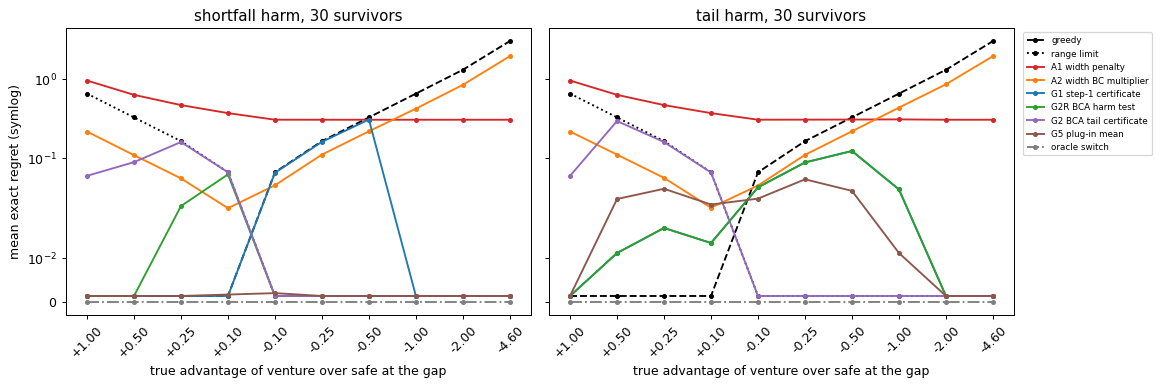

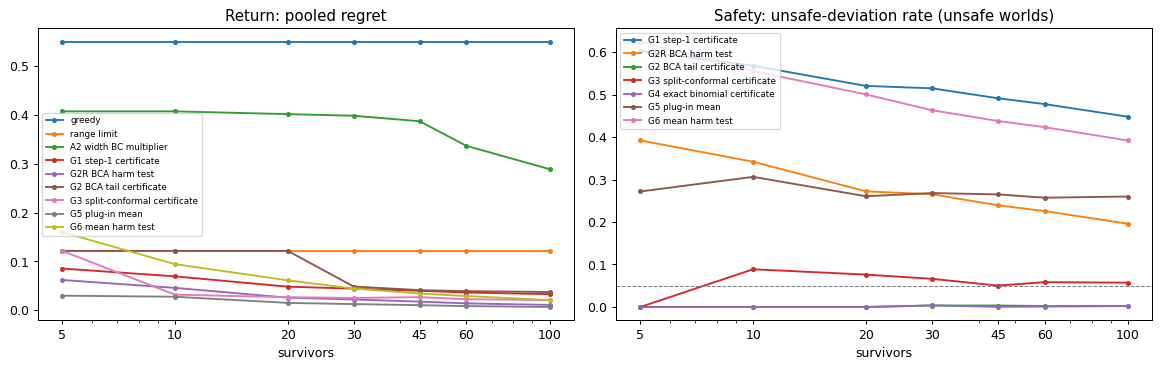

In [18]:
lines = ["greedy", "range limit", "A1 width penalty", "A2 width BC multiplier", "G1 step-1 certificate",
         "G2R BCA harm test", "G2 BCA tail certificate", "G5 plug-in mean", "oracle switch"]
styles = dict(zip(lines, ["k--", "k:", "C3-", "C1-", "C0-", "C2-", "C4-", "C5-", "C7-."]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
i30 = EVIDENCE.index(30)
for h, harm in enumerate(HARMS):
    ax = axes[h]
    for m in lines:
        ax.plot(range(len(ADV)), REG[:, i30, h, :, M[m]].mean(axis=0), styles[m], marker="o", ms=3, label=m)
    ax.set_xticks(range(len(ADV))); ax.set_xticklabels([f"{a:+.2f}" for a in ADV], rotation=45)
    ax.set_yscale("symlog", linthresh=0.02)
    ax.set_title(f"{harm} harm, 30 survivors")
    ax.set_xlabel("true advantage of venture over safe at the gap")
axes[0].set_ylabel("mean exact regret (symlog)")
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for m in ["greedy", "range limit", "A2 width BC multiplier", "G1 step-1 certificate", "G2R BCA harm test",
          "G2 BCA tail certificate", "G3 split-conformal certificate", "G5 plug-in mean", "G6 mean harm test"]:
    axes[0].plot(EVIDENCE, [REG[:, i, ..., M[m]].mean() for i in range(len(EVIDENCE))], marker="o", ms=3, label=m)
for m in ["G1 step-1 certificate", "G2R BCA harm test", "G2 BCA tail certificate", "G3 split-conformal certificate",
          "G4 exact binomial certificate", "G5 plug-in mean", "G6 mean harm test"]:
    axes[1].plot(EVIDENCE, [DEV[:, i, ..., M[m]][unsafe_mask[:, i]].mean() for i in range(len(EVIDENCE))],
                 marker="o", ms=3, label=m)
axes[1].axhline(1 - BETA, color="grey", lw=0.8, ls="--")
axes[0].set_title("Return: pooled regret"); axes[1].set_title("Safety: unsafe-deviation rate (unsafe worlds)")
for ax in axes:
    ax.set_xscale("log"); ax.set_xticks(EVIDENCE); ax.set_xticklabels(EVIDENCE); ax.set_xlabel("survivors")
    ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

**Checks.** These confirm that the toy works as described; any failure stops the notebook. The last two printed lines confirm that BCA's width really is calibrated where it is measured, at logged actions.

In [19]:
# 1. Outcome laws normalize, and the gap mean is 1 + advantage in both shapes.
for harm in HARMS:
    for adv in ADVANTAGE:
        lw = gap_law(harm, adv)
        assert np.isclose(sum(p for p, _ in lw), 1) and all(p >= 0 for p, _ in lw)
        assert np.isclose(sum(p * m for p, m in lw), 1 + adv)
# 2. Worlds are paired: the same log and the same survivor random numbers.
tr, ca, sv = collect(0)
tr2, ca2, sv2 = collect(0)
assert all(np.array_equal(tr[k], tr2[k]) and np.array_equal(ca[k], ca2[k]) for k in tr)
assert np.allclose(survivor_rewards(sv, "shortfall", 0.5, 30) - survivor_rewards(sv, "shortfall", -1.0, 30), 1.5)
# 3. The critic never trains on survivors, and wants the gap action in every seed (asserted in run_seed).
q0, n0 = fit_critic(tr)
assert n0[1, 1, VENTURE] == 0
# 4. Regrets are non-negative, the oracle's is zero, and the gate rules differ from greedy only at the gap.
assert np.all(REG >= -1e-12) and np.allclose(REG[..., M["oracle switch"]], 0)
away = REG[..., M["greedy"]] - gap_cost(np.ones(DEV.shape[:4], dtype=bool))
for m in GATES:
    assert np.allclose(REG[..., M[m]], away + gap_cost(DEV[..., M[m]]))
# 5. Exact algebra behind test 4a: BCA's infinite-draw certificate equals the exact binomial test.
rng = np.random.default_rng([ROOT_SEED, 998])
for _ in range(2000):
    n = int(rng.integers(5, 120)); s = rng.standard_normal(n); a = float(rng.normal(1.0, 0.5))
    assert (bca_exact(s) <= a) == (binom_cdf(int((s > a).sum()), n, ALPHA) <= 1 - BETA)
# 6. The width is calibrated where it is measured: coverage of A1's widths on fresh logged rows.
sc0, un0 = fit_scale(tr, q0)
r0_ = bca_exact(np.abs(targets(ca, 0, q0) - q0[0, ca["c"], ca["a"][:, 0]]) / sc0[0, ca["c"], ca["a"][:, 0]])
r1_ = bca_exact(np.abs(targets(ca, 1, q0) - q0[1, ca["c"], ca["a"][:, 1]]) / sc0[1, ca["c"], ca["a"][:, 1]])
fresh = collect(10_000)[1]
for t, r_ in ((0, r0_), (1, r1_)):
    cov = (np.abs(targets(fresh, t, q0) - q0[t, fresh["c"], fresh["a"][:, t]])
           <= r_ * sc0[t, fresh["c"], fresh["a"][:, t]]).mean()
    print(f"A1 width coverage at recorded actions, stage {t}: {cov:.3f} (target at least {1 - ALPHA:.2f})")
    assert cov >= 0.85
print("All checks passed. Notebook seconds:", round(time.perf_counter() - START, 1))

A1 width coverage at recorded actions, stage 0: 0.902 (target at least 0.90)
A1 width coverage at recorded actions, stage 1: 0.935 (target at least 0.90)
All checks passed. Notebook seconds: 44.5


**Information only (written after the run).** First, for each world with 30 survivors, the share of seeds in which each rule ventures at the gap. A * marks unsafe worlds; venture is better on average when the advantage is above 0. Then the worst unsafe world by number of survivors, and how spread out the step-1 gate's comparison group is.

In [20]:
# Added after the run, information only: per-world decisions at 30 survivors, the worst single unsafe world,
# and the spread of the reference group that the step-1 gate compares against.
i30 = EVIDENCE.index(30)
show = ["range limit", "A2 width BC multiplier", "G1 step-1 certificate", "G2R BCA harm test",
        "G2 BCA tail certificate", "G3 split-conformal certificate", "G5 plug-in mean"]
for h, harm in enumerate(HARMS):
    print(f"{harm}: share of seeds that venture at the gap with 30 survivors "
          "(* unsafe world; venture is better on average when the advantage is above 0)")
    print(f"{'rule':31}" + "".join(f"{a:+7.2f}{'*' if UNSAFE[h, w] else ' '}" for w, a in enumerate(ADV)))
    for m in show:
        print(f"{m:31}" + "".join(f"{DEV[:, i30, h, w, M[m]].mean():7.2f} " for w in range(len(ADV))))
    print()
print("Worst single unsafe world: share of seeds that venture there, by evidence size")
for m in ["G2 BCA tail certificate", "G4 exact binomial certificate", "G3 split-conformal certificate",
          "G2R BCA harm test", "G5 plug-in mean"]:
    worst = [DEV[:, k, :, :, M[m]].mean(axis=0)[UNSAFE].max() for k in range(len(EVIDENCE))]
    print(f"{m:31}", "  ".join(f"n={ne}: {v:.2f}" for ne, v in zip(EVIDENCE, worst)))
med, low, share = [], [], []
for seed in range(N_SEEDS):
    train, cal, _ = collect(seed)
    q, _ = fit_critic(train)
    rng = np.random.default_rng([ROOT_SEED, seed, 1])
    rng.standard_exponential((DRAWS, max(EVIDENCE) + 1))   # the gap's draws, as in run_seed
    s_rest = q[1, cal["c"], cal["a"][:, 1]] - cal["r"][:, 1]
    cross = bca(s_rest, rng.standard_exponential((DRAWS, s_rest.size + 1)))[1]
    med.append(np.median(cross)); low.append(np.quantile(cross, 0.05))
    share.append(np.mean((cal["c"] == 0) & (cal["a"][:, 1] == VENTURE) & (cal["r"][:, 1] < 1.5)))
print(f"\nThe step-1 gate's reference group (all other final-step calibration rows), over {N_SEEDS} seeds:")
print(f"  posterior median of its 90% crossing: mean {np.mean(med):.2f}, from {min(med):.2f} to {max(med):.2f}")
print(f"  5% posterior quantile of that crossing: mean {np.mean(low):.2f}")
print(f"  share of its rows that are the noisy cell's low outcomes (over-prediction near 1.5): {np.mean(share):.3f}")

shortfall: share of seeds that venture at the gap with 30 survivors (* unsafe world; venture is better on average when the advantage is above 0)
rule                             +1.00   +0.50   +0.25*  +0.10*  -0.10*  -0.25*  -0.50*  -1.00*  -2.00*  -4.60*
range limit                       0.00    0.00    0.00    0.00    0.00    0.00    0.00    0.00    0.00    0.00 
A2 width BC multiplier            0.67    0.67    0.67    0.67    0.67    0.67    0.67    0.65    0.65    0.65 
G1 step-1 certificate             1.00    1.00    1.00    1.00    0.98    0.98    0.94    0.00    0.00    0.00 
G2R BCA harm test                 1.00    1.00    0.85    0.06    0.00    0.00    0.00    0.00    0.00    0.00 
G2 BCA tail certificate           0.91    0.73    0.03    0.00    0.00    0.00    0.00    0.00    0.00    0.00 
G3 split-conformal certificate    1.00    0.99    0.35    0.01    0.00    0.00    0.00    0.00    0.00    0.00 
G5 plug-in mean                   1.00    1.00    1.00    0.99    0.01 

## What Part 2 found

| Test | Claim | Result | Verdict |
|---|---|---|---|
| 1 | BCA's width at every action (A1, A2) removes at least a quarter of the room | −2.50 and −2.09 of the room: worse than refusing thin data | shelved |
| 2 | The step-1 gate (G1) removes at least half the room, and shuffled outcomes keep at most half of that | +0.58; shuffled outcomes keep none | alive |
| 3 | Comparing with the critic's claimed advantage beats step 1's margin against the rest | regret 0.028 against 0.051 | alive |
| 4a | BCA decides differently from the exact binomial test | 99.6% agreement | shelved |
| 4b | BCA's confidence makes deviations safer than split conformal | 5.5 points safer, against a 5-point bar | alive, narrowly |
| 4c | Safety needs a quantile, not an average | 28.8 points safer, against a 5-point bar | alive |

- **BCA's width at every action did worse than refusing thin data (test 1, shelved).**
  - *The idea:* BCA's calibrated width puts caution where the critic is wrong, either as a penalty at every action (A1) or as production's multiplier on the host's pull toward logged actions (A2).
  - *What we tested (and the kill rule):* both rules against refusing thin data, pooled over 200 seeds, both harm shapes, the ten worlds and seven numbers of survivors. Each is shelved if it removes less than a quarter of the room.
  - *What happened:* regret 0.425 (A1) and 0.376 (A2), against 0.122. A2 beat the plain host actor (0.494), but through blanket caution: with 30 survivors, it ventured at the gap in about two thirds of seeds in every world. A1's gap decision changed across the ten worlds in at most 1% of seeds. The widths were still calibrated where measured: they covered 90.2% and 93.5% of fresh logged rows, against a 90% target.
  - *Why:* the width is measured at logged actions, and the gap has none. The survivors are a small share of a pooled bank of about 600 rows, too few to move the one shared threshold. Meanwhile, the penalty also hits good actions that are merely noisy, which cost A1 about 0.30 of regret.
- **Gates that read the survivors helped.** They removed 38% to 87% of the room. With shuffled outcomes, the step-1 gate and the harm test did worse than refusing thin data, and the tail certificate only matched it.
- **What a gate compares with matters more than BCA's posterior.** The step-1 gate asks whether the survivors' over-predictions exceed those of every other last-step row by more than 0.10. That comparison point is unstable: its posterior median ran from 0.35 to 1.50 across seeds. In the shortfall shape, the step-1 gate ventured in 94–98% of seeds at advantages −0.10 to −0.50, where venture is worse. Comparing with the critic's claimed advantage stopped all of those, and regret fell from 0.051 to 0.028.
- **Compared with the claimed advantage, the critic drops out.** The score is q(venture) − outcome, and the claimed advantage is q(venture) − q(safe). So "score at most the claimed advantage" is the same as "outcome at least q(safe)". The gate is really a test of the survivors' outcomes against the safe action's value, which the critic estimates well because the safe action is in the data.
- **For return, the plain average won.** The survivors' plain average against the safe action's value (G5) had the lowest regret at every number of survivors: 0.016 overall, and 0.030 even with 5 survivors.
- **For safety, BCA's tail certificate won.** It and its exact twin ventured in at most 3% of seeds in every unsafe world. Split conformal reached 32–38% in its worst world, because its promise holds on average over data sets, not for the data in hand. The plain average ventured in every seed of its worst unsafe world. The certificate's price was 0.060 more regret than the plain average, and it cannot decide with fewer than 29 survivors.
- **With equal weights, BCA is a textbook test (test 4a, shelved).**
  - *The idea:* BCA's Bayesian posterior adds information that a classical test lacks.
  - *What we tested (and the kill rule):* the BCA tail certificate (G2) against the exact binomial certificate (G4), case by case; shelved if they agree in at least 99% of cases.
  - *What happened:* they agreed in 99.6%. The rest were random-sampling slips with 1,000 draws; with 100,000 draws, every case agreed.
  - *Why:* with equal weights, BCA's threshold is one of the sorted scores, picked by a binomial tail. That is the exact binomial (Clopper–Pearson) test, which is also Wilks' (1941) tolerance limit and Vovk's (2012) training-conditional conformal bound.

**The insight.** The useful signal is the risky action's own held-out outcomes, measured against the fallback's value. Which statistic to use depends on the promise: an average for return, a tail certificate for "rarely worse than the fallback". With equal weights, BCA adds no information over a textbook test; what it adds is the kind of promise its answer carries. Its one non-textbook part, weighting, could not matter in this world. Part 3 tests a BCA gate built for return, and Part 4 tests the weights.

---
# Part 3. Can a BCA gate raise return? The mean gate

*Pre-registered. Original notebook: `bca_mean_gate_toy.ipynb`. Kill rules fingerprint `50a0f49d…b1d3`.*

**The question.** Part 2's tail gate asks whether at least 90% of outcomes beat the fallback, which is the wrong question for return. The **BCA mean gate** asks whether the risky action beats the fallback on average, and promises to say yes to a harmful action at most 5% of the time. When every gate must be equally safe, does it earn the most?

**The setup.**
- The policy faces **situations**. In each, it can take the **safe action** (worth 0) or one of several **candidate** actions. Each candidate has a true average gain over safe: above 0 means **good**, below 0 means **harmful**. Only the scoring knows these numbers.
- The log holds a few **tries** of each candidate (5 to 100), plus a separate **held-out** set of the same size.
- **Step 1, the critic proposes.** It picks the candidate with the best training average, if that average is above 0. With many candidates, it is often fooled by one that got lucky.
- **Step 2, the gate decides.** Looking only at the proposal's held-out tries, it accepts or stays safe.
- **The score** is the true average gain of the final choice; staying safe scores 0.

This mirrors offline reinforcement learning: the critic likes actions the log barely covers, and the safe action is what the log usually did.

**The worlds.** Each try's gain follows one of three shapes:

| Shape | A typical try | Why it is hard |
|---|---|---|
| Steady | the true average plus noise (spread 1) | the noise is large next to the average |
| Rare disaster | a small gain (0.2 to 0.6), but sometimes a loss of 8 | a few tries often show no disaster |
| Rare jackpot | a small loss (0.1 to 0.4), but sometimes a gain of 8 | a few tries often show no jackpot |

- A try's gain always stays inside a known range: −3 to 3 (steady), −8 to 3 (rare disaster), −3 to 8 (rare jackpot). The bottom of the range is the **floor**. Gates may use the range.
- A world combines one shape, one share of good candidates (10%, 30% or 50%) and one number of candidates per situation (1, 3, 10 or 30). That makes 36 worlds, each run on 200 seeds of 20 situations.
- Seeds 0–99 are used only to tune knobs (claim 5); every other result uses seeds 100–199. All worlds share the same random numbers.

### The gates

"Promise 5%" means the gate accepts a harmful proposal at most 5% of the time, in every world.

| Gate | Accepts the proposal when | Promise |
|---|---|---|
| always safe | never | nothing to promise |
| no gate | always (the critic decides alone) | none |
| count rule | it has at least 30 held-out tries (like SPIBB, a count-based safe-improvement method) | none |
| plain average | the held-out average is above 0 | none |
| shrunk average | the held-out average, pulled toward the average of all candidates in the seed's 20 situations, is above 0 | none |
| BCA average | (sum of tries + floor) ÷ (tries + 1) is above 0 | none |
| t-test | the t-test's 95% lower bound on the average is above 0 | 5%, if outcomes are roughly bell-shaped |
| Hoeffding | Hoeffding's 95% lower bound (uses only the range) is above 0 | 5% |
| empirical Bernstein | the empirical Bernstein 95% lower bound (range and spread) is above 0 | 5% |
| **BCA mean gate** | BCA's 95% lower bound on the average is above 0 (see below) | 5% * |
| BCA tail gate (as built) | BCA is 95% sure that at least 90% of tries beat 0 | 5%, about the 90% share |
| split-conformal tail | the 10th-percentile held-out try (with the usual conformal rounding) is above 0 | about the 90% share, only on average over data sets |
| BCA mean gate, shared budget | the 20 situations are decided together, letting more through when many look good (the Benjamini–Hochberg method) | on average, at most 10% of acceptances are harmful |
| oracle gate | the proposal is truly good | scoring reference only |

A **95% lower bound** is a value that the true average is above with 95% confidence. A gate built on one accepts when the bound is above 0.

\* The proof that this bound keeps its promise is in a July 2026 preprint ([Vlassis and Thomas](https://arxiv.org/abs/2607.08415)) that is not yet peer reviewed. Claim 1 tests the promise.

BCA's tail gate is computed in its exact form here; Part 2 showed that BCA's random sampler gives the same answer.

### How BCA's mean gate works

BCA already gives each held-out try a random weight, plus one extra weight for a worst case. The tail gate uses those weights to check the 90% share. The mean gate uses the same weights differently:
1. Put the extra weight on the **floor**, the worst gain a try can have.
2. For each of 10,000 random weightings, take the weighted average of the tries and the floor.
3. Accept if at most 5% of those averages are below 0.

This is the same calculation as Gaffke's (2005) bound on an average, which the [Learned-Miller–Thomas bound](https://arxiv.org/abs/1905.06208) matches ([Ming and others](https://arxiv.org/html/2607.18661)). Of the guaranteed small-sample bounds the research reviewed, it was the tightest. The extra weight on the floor keeps it honest: a harmful candidate that showed no disaster in a few tries still pays for the disaster it might be hiding. The next cell shows, before any experiment, how much clean evidence each guaranteed gate needs.

In [21]:
import math, time, hashlib
from fractions import Fraction
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt

START = time.perf_counter()
ROOT_SEED, STREAM = 20261014, 41
N_SEEDS, SITUATIONS, CMAX = 200, 20, 30
TUNE_SEEDS, EVAL_SEEDS = np.arange(0, 100), np.arange(100, 200)
SHAPES = ("steady", "rare disaster", "rare jackpot")
GOOD_SHARES = (0.1, 0.3, 0.5)
CANDIDATES = (1, 3, 10, 30)
N_MIN, N_MAX = 5, 100
FLOOR = {"steady": -3.0, "rare disaster": -8.0, "rare jackpot": -3.0}
CEILING = {"steady": 3.0, "rare disaster": 3.0, "rare jackpot": 8.0}
BIG = 8.0
DELTA = 0.05                    # stated level: accept a harmful proposal at most 5% of the time
DRAWS = 10_000                  # BCA's random weightings per decision
TAIL, CONFIDENCE = 0.1, 0.95    # BCA's tail gate as built: at least 90% of tries beat 0, 95% sure
COUNT_NEED = 30
BUDGET = 0.10                   # harm budget of the shared-budget gate
MARGINS = (0.0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0)
LEVELS = (0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001)
TAIL_SHARES = (0.5, 0.4, 0.3, 0.2, 0.1, 0.05)
COUNTS = (5, 10, 20, 30, 50, 80, 100)
assert CMAX == max(CANDIDATES) and 0 < DELTA < 1

In [22]:
def smallest_gain_mean_gate(n, floor=-1.0):
    """Smallest gain the BCA mean gate accepts when all n tries show that same gain (exact; see check 2)."""
    r = DELTA ** (1 / n)
    return -floor * (1 - r) / r

print("Every held-out try shows the same gain g; gains range from -1 to +1. Smallest g each gate accepts:")
print("held-out tries   BCA mean gate   Hoeffding   empirical Bernstein   t-test")
show = lambda v: f"{v:.2f}" if v <= 1 else "never"
for n in (10, 29, 100):
    hoeffding = 2 * math.sqrt(math.log(1 / DELTA) / (2 * n))
    bernstein = 7 * 2 * math.log(2 / DELTA) / (3 * (n - 1))
    print(f"{n:>14}   {show(smallest_gain_mean_gate(n)):>13}   {show(hoeffding):>9}   {show(bernstein):>19}   any g above 0")

n, p_loss = 29, 0.05
clean = (1 - p_loss) ** n
print(f"\nA candidate gains 0.4 on 95% of tries and loses 10 on the rest (true average -0.12, so harmful).")
print(f"With {n} tries, {clean:.0%} of samples contain no loss. The t-test sees no spread in those and accepts,")
print(f"so it accepts this harmful action about {clean:.0%} of the time instead of 5%.")
print(f"Told that the floor is -10, the BCA mean gate puts {(10 / 10.4) ** n:.0%} of its weighted averages below 0")
print("for those same clean samples, far more than 5%, so it refuses.")

Every held-out try shows the same gain g; gains range from -1 to +1. Smallest g each gate accepts:
held-out tries   BCA mean gate   Hoeffding   empirical Bernstein   t-test
            10            0.35        0.77                 never   any g above 0
            29            0.11        0.45                  0.61   any g above 0
           100            0.03        0.24                  0.17   any g above 0

A candidate gains 0.4 on 95% of tries and loses 10 on the rest (true average -0.12, so harmful).
With 29 tries, 23% of samples contain no loss. The t-test sees no spread in those and accepts,
so it accepts this harmful action about 23% of the time instead of 5%.
Told that the floor is -10, the BCA mean gate puts 32% of its weighted averages below 0
for those same clean samples, far more than 5%, so it refuses.


### What would shelve each claim

The binding version is the kill-rule text in the code below. A world's **allowance** on a 5% harm rate is 5% plus three standard errors for that world's number of harmful proposals.
1. **BCA's mean gate keeps its promise.** Shelved if its harm rate is above the allowance in any world.
2. **It is the tightest guaranteed mean gate.** Shelved unless it accepts at least 5 points more of the good proposals than both Hoeffding and empirical Bernstein.
3. **A t-test gate is not safe when disasters are rare.** Shelved if the t-test's harm rate is within the allowance in every rare-disaster world.
4. **Where many candidates compete and few are good, the mean gate earns more than simple averaging.** Shelved unless, over the 12 crowded worlds, it earns more than both the plain and the shrunk average.
5. **At equal harm, the mean gate earns the most.** On seeds 0–99, each gate takes its best setting among those with at most 5% harm in every world. Shelved if any other tuned gate earns at least as much on seeds 100–199.
6. **Deciding the 20 situations together, with a shared 10% harm budget, earns more than deciding each alone.** Shelved unless it earns more, with at most 12% harmful acceptances on average in every world.

In [23]:
_erf = np.frompyfunc(math.erf, 1, 1)
def Phi(x): return 0.5 * (1 + np.asarray(_erf(np.asarray(x, dtype=float) / math.sqrt(2)), dtype=float))
def phi(x):
    x = np.asarray(x, dtype=float)
    return np.exp(-0.5 * x * x) / math.sqrt(2 * math.pi)

def clipped_mean(center, spread, lo=-3.0, hi=3.0):
    """Exact average of clip(center + spread * Z, lo, hi) for a standard normal Z."""
    a, b = (lo - center) / spread, (hi - center) / spread
    return lo * Phi(a) + hi * (1 - Phi(b)) + center * (Phi(b) - Phi(a)) + spread * (phi(a) - phi(b))

def candidates(shape, good, v1, v2):
    """Outcome parameters and exact average gain of each candidate; v1 and v2 are uniform numbers in (0, 1)."""
    if shape == "steady":
        center = np.where(good, 0.05 + 0.45 * v1, -(0.05 + 0.55 * v1))
        return {"center": center, "spread": 1.0, "chance": np.zeros_like(v1), "mean": clipped_mean(center, 1.0)}
    if shape == "rare disaster":
        center = 0.2 + 0.4 * v2
        usual = clipped_mean(center, 0.3)
        even = usual / (usual + BIG)                       # disaster chance that makes the average exactly 0
        chance = np.where(good, 0.7 * even * v1, 1.3 * even + (0.2 - 1.3 * even) * v1)
        return {"center": center, "spread": 0.3, "chance": chance, "mean": (1 - chance) * usual - chance * BIG}
    center = -(0.1 + 0.3 * v2)
    usual = clipped_mean(center, 0.3)                      # the usual small loss (negative)
    even = -usual / (BIG - usual)                          # jackpot chance that makes the average exactly 0
    chance = np.where(good, 1.3 * even + (0.12 - 1.3 * even) * v1, 0.7 * even * v1)
    return {"center": center, "spread": 0.3, "chance": chance, "mean": (1 - chance) * usual + chance * BIG}

def tries(shape, cand, u, z):
    """Gains of tries; u and z hold one uniform and one normal number per try (last axis)."""
    usual = np.clip(cand["center"][..., None] + cand["spread"] * z, -3.0, 3.0)
    if shape == "steady":
        return usual
    big = -BIG if shape == "rare disaster" else BIG
    return np.where(u < cand["chance"][..., None], big, usual)

def shrink(means, variances, counts):
    """Empirical-Bayes shrinkage of each candidate's held-out average toward the average of all candidates in play."""
    pooled = ((counts - 1) * variances).sum() / (counts - 1).sum()
    noise = pooled / counts
    center = means.mean()
    spread = max(0.0, ((means - center) ** 2).mean() - noise.mean())
    return center + spread / (spread + noise) * (means - center)

@lru_cache(maxsize=None)
def t_upper(level, df):
    """t with P(T > t) = level for Student's t with df degrees of freedom (Simpson's rule and bisection)."""
    c = math.exp(math.lgamma((df + 1) / 2) - math.lgamma(df / 2)) / math.sqrt(df * math.pi)
    w = np.ones(2001)
    w[1:-1:2], w[2:-1:2] = 4, 2
    def tail(t):
        x = np.linspace(0.0, t, 2001)
        return 0.5 - t / 6000 * (w * c * (1 + x * x / df) ** (-(df + 1) / 2)).sum()
    lo, hi = 0.0, 1.0
    while tail(hi) > level:
        hi *= 2
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if tail(mid) > level else (lo, mid)
    return hi

@lru_cache(maxsize=None)
def allowed_below(n, share, confidence=CONFIDENCE):
    """BCA's tail gate as built, in exact form: the most tries that may fall below 0, or -1 if none may."""
    cdf, best = 0.0, -1
    for x in range(n + 1):
        cdf += math.exp(math.lgamma(n + 1) - math.lgamma(x + 1) - math.lgamma(n - x + 1)
                        + x * math.log(share) + (n - x) * math.log1p(-share))
        if cdf > 1 - confidence:
            break
        best = x
    return best

def by_count(fn):
    """fn evaluated at every possible number of tries 0..N_MAX, for lookups by count."""
    return np.array([fn(k) for k in range(N_MAX + 1)])

In [24]:
KILL_RULES = """
Written before the first run of this notebook. Not to be changed after seeing the results.

Words used. A proposal is harmful when its true average gain over the safe action is below zero, and good when
it is above zero. In a world, a gate's harm rate is the share of harmful proposals it accepts, and its gain is
the true average gain of the final choice per situation (always staying safe scores 0). A world is one
combination of outcome shape (3), share of good candidates (3) and number of candidates (4), so there are 36.
Results use seeds 100-199 (20 situations each) and each gate's stated setting, unless a claim says otherwise.
Pooled means averaged over the 36 worlds with equal weight. Crowded worlds are the 12 worlds with 10 or 30
candidates and 10% or 30% good candidates. A world's allowance on a 5% harm rate is 0.05 plus three standard
errors, 3 * sqrt(0.05 * 0.95 / h), where h is that world's number of harmful proposals.

Claim 1. BCA's mean gate keeps its promise. Shelved if its harm rate is above the allowance in any world.

Claim 2. BCA's mean gate is the tightest of the guaranteed mean gates. Shelved unless, over all worlds together,
the share of good proposals it accepts is at least 0.05 above Hoeffding's and at least 0.05 above empirical
Bernstein's.

Claim 3. A t-test gate is not safe when disasters are rare. Shelved if the t-test gate's harm rate is within the
allowance in every rare-disaster world.

Claim 4. Where many candidates compete and few are good, BCA's mean gate earns more than simple averaging.
Shelved if its pooled gain over the crowded worlds is not above both the plain-average gate's and the
shrunk-average gate's.

Claim 5. At equal harm, BCA's mean gate earns the most. On seeds 0-99, each tunable gate takes the setting from
its fixed grid with the highest pooled gain among settings whose harm rate is at most 0.05 in every world; a
gate with no such setting always stays safe. Shelved if, on seeds 100-199, any other tuned gate's pooled gain
is at least the tuned BCA mean gate's.

Claim 6. Deciding the 20 situations together under a 10% harm budget (Benjamini-Hochberg on BCA's mean-gate
p-values) earns more than deciding each situation alone. Shelved if its pooled gain is not above the
per-situation BCA mean gate's, or if, in any world, the average share of harmful proposals among its
acceptances is above 0.12.
"""
print("Kill rules fingerprint (SHA-256):", hashlib.sha256(KILL_RULES.encode()).hexdigest())

Kill rules fingerprint (SHA-256): 50a0f49d678b2205e2dba3af5ea741d8cbc887679127ccdd8612f2c43f93b1d3


**The run.** For each seed, the next cell draws every candidate, its tries and BCA's 10,000 random weightings once, and reuses them in all 36 worlds. The cell after it turns each gate into decisions.

In [25]:
FIELDS = ("exists", "mu", "n", "mean", "var", "below", "neg", "shrunk", "best")

def run_seed(seed, flip_held=False):
    rng = np.random.default_rng([ROOT_SEED, STREAM, seed])
    n = np.rint(np.exp(rng.uniform(math.log(N_MIN), math.log(N_MAX), (SITUATIONS, CMAX)))).astype(int)
    good_u, v1, v2 = rng.random((3, SITUATIONS, CMAX))
    tr_u, ho_u = rng.random((2, SITUATIONS, CMAX, N_MAX))
    tr_z, ho_z = rng.standard_normal((2, SITUATIONS, CMAX, N_MAX))
    if flip_held:                                                # used only by check 6
        ho_u, ho_z = 1 - ho_u, -ho_z
    weights = rng.standard_exponential((DRAWS, N_MAX + 1))       # one per try, and the last one for the floor
    inside = np.arange(N_MAX) < n[..., None]
    rows = np.arange(SITUATIONS)
    rec = {f: np.zeros((len(SHAPES), len(GOOD_SHARES), len(CANDIDATES), SITUATIONS)) for f in FIELDS}
    for si, shape in enumerate(SHAPES):
        for gi, share in enumerate(GOOD_SHARES):
            cand = candidates(shape, good_u < share, v1, v2)
            train = np.where(inside, tries(shape, cand, tr_u, tr_z), 0.0)
            held = np.where(inside, tries(shape, cand, ho_u, ho_z), 0.0)
            tr_mean, ho_mean = train.sum(-1) / n, held.sum(-1) / n
            ho_var = np.where(inside, (held - ho_mean[..., None]) ** 2, 0.0).sum(-1) / (n - 1)
            ho_below = (inside & (held < 0)).sum(-1)
            picks = []
            for mi, m in enumerate(CANDIDATES):
                j = tr_mean[:, :m].argmax(axis=1)                  # the critic sees training tries only
                picks.append(j)
                shrunk = shrink(ho_mean[:, :m], ho_var[:, :m], n[:, :m])
                values = {"exists": tr_mean[rows, j] > 0, "mu": cand["mean"][rows, j], "n": n[rows, j],
                          "mean": ho_mean[rows, j], "var": ho_var[rows, j], "below": ho_below[rows, j],
                          "shrunk": shrunk[rows, j], "best": np.maximum(0.0, cand["mean"][:, :m].max(axis=1))}
                for f, v in values.items():
                    rec[f][si, gi, mi] = v
            # BCA mean gate: count the weighted averages below 0. A weighted average is below 0 exactly when
            # its weighted sum is, because the weights are positive.
            pairs = sorted({(s, int(j[s])) for j in picks for s in rows})
            index = {p: k for k, p in enumerate(pairs)}
            x = np.stack([held[s, c] for s, c in pairs], axis=1)   # one column per proposal, 0 past its n
            sums = weights[:, :N_MAX] @ x + weights[:, N_MAX:] * FLOOR[shape]
            negative = (sums < 0).sum(axis=0)
            for mi, j in enumerate(picks):
                rec["neg"][si, gi, mi] = negative[[index[(s, int(j[s]))] for s in rows]]
    return rec

records = [run_seed(s) for s in range(N_SEEDS)]
R = {f: np.stack([r[f] for r in records]) for f in FIELDS}     # axes: seed, shape, good share, candidates, situation
EXISTS = R["exists"].astype(bool)
MU, NTRY, MEAN, VAR = R["mu"], R["n"].astype(int), R["mean"], R["var"]
BELOW, NEG, SHRUNK, BEST = R["below"].astype(int), R["neg"].astype(int), R["shrunk"], R["best"]
FLOORS = np.array([FLOOR[s] for s in SHAPES])[None, :, None, None, None]
RANGES = np.array([CEILING[s] - FLOOR[s] for s in SHAPES])[None, :, None, None, None]
HARMFUL, GOOD = EXISTS & (MU < 0), EXISTS & (MU > 0)
print(f"{N_SEEDS} seeds in {time.perf_counter() - START:.0f} s. The critic proposed something in "
      f"{EXISTS.mean():.0%} of situations: {GOOD.sum():,} good proposals and {HARMFUL.sum():,} harmful ones.")

200 seeds in 18 s. The critic proposed something in 75% of situations: 79,355 good proposals and 28,508 harmful ones.


In [26]:
def bh(neg, budget):
    """Benjamini-Hochberg across the 20 situations of each seed and world, on the mean gate's p-values."""
    p = np.where(EXISTS, (neg + 1) / (DRAWS + 1), np.inf)
    out = np.zeros_like(EXISTS)
    flat_p, flat_out = p.reshape(-1, SITUATIONS), out.reshape(-1, SITUATIONS)
    for k in range(flat_p.shape[0]):
        m = np.isfinite(flat_p[k]).sum()
        if m == 0:
            continue
        order = np.argsort(flat_p[k])
        passed = flat_p[k][order] <= budget * np.arange(1, SITUATIONS + 1) / m
        if passed.any():
            flat_out[k, order[:np.nonzero(passed)[0].max() + 1]] = True
    return out

def limit(level):
    return math.floor(Fraction(str(level)) * DRAWS)

def accept(gate, knob=None):
    """Which proposals a gate accepts, at its stated setting or at knob."""
    level = DELTA if knob is None else knob
    margin = 0.0 if knob is None else knob
    if gate == "always safe":
        d = np.zeros_like(EXISTS)
    elif gate == "no gate":
        d = np.ones_like(EXISTS)
    elif gate == "oracle gate":
        d = MU > 0
    elif gate == "count rule":
        d = NTRY >= (COUNT_NEED if knob is None else knob)
    elif gate == "plain average":
        d = MEAN > margin
    elif gate == "shrunk average":
        d = SHRUNK > margin
    elif gate == "BCA average":
        d = (MEAN * NTRY + FLOORS) / (NTRY + 1) > margin
    elif gate == "t-test":
        tq = by_count(lambda k: t_upper(level, k - 1) if k >= 2 else math.inf)[NTRY]
        d = MEAN - tq * np.sqrt(VAR / NTRY) > 0
    elif gate == "Hoeffding":
        d = MEAN - RANGES * np.sqrt(math.log(1 / level) / (2 * NTRY)) > 0
    elif gate == "empirical Bernstein":
        d = (MEAN - np.sqrt(2 * VAR * math.log(2 / level) / NTRY)
             - 7 * RANGES * math.log(2 / level) / (3 * (NTRY - 1))) > 0
    elif gate == "BCA mean gate":
        d = NEG <= limit(level)
    elif gate == "BCA mean gate, shared budget":
        d = bh(NEG, BUDGET if knob is None else knob)
    elif gate == "BCA tail gate":
        share = TAIL if knob is None else knob
        d = BELOW <= by_count(lambda k: allowed_below(k, share) if k >= 1 else -1)[NTRY]
    elif gate == "split-conformal tail":
        share = TAIL if knob is None else knob
        rank = by_count(lambda k: math.floor(Fraction(str(share)) * (k + 1)))[NTRY]
        d = (rank >= 1) & (BELOW < rank)
    else:
        raise KeyError(gate)
    return d & EXISTS

def harm_by_world(d, seeds):
    h = HARMFUL[seeds]
    return (d[seeds] & h).sum(axis=(0, 4)) / np.maximum(h.sum(axis=(0, 4)), 1)

def gain_by_world(d, seeds):
    return np.where(d[seeds], MU[seeds], 0.0).mean(axis=(0, 4))

def good_accepted(d, seeds):
    return (d[seeds] & GOOD[seeds]).sum() / GOOD[seeds].sum()

def false_share_by_world(d, seeds):
    accepted, bad = d[seeds].sum(axis=4), (d[seeds] & HARMFUL[seeds]).sum(axis=4)
    return np.where(accepted > 0, bad / np.maximum(accepted, 1), 0.0).mean(axis=0)

def allowance(seeds):
    h = HARMFUL[seeds].sum(axis=(0, 4))
    return DELTA + 3 * np.sqrt(DELTA * (1 - DELTA) / np.maximum(h, 1))

GATES = ["always safe", "no gate", "count rule", "plain average", "shrunk average", "BCA average", "t-test",
         "Hoeffding", "empirical Bernstein", "BCA mean gate", "BCA tail gate", "split-conformal tail",
         "BCA mean gate, shared budget", "oracle gate"]
DEC = {g: accept(g) for g in GATES}
ORACLE_GAIN = gain_by_world(DEC["oracle gate"], EVAL_SEEDS).mean()

### Results

**How to read the table.** Each row is one gate at its stated setting, on seeds 100–199.
- **gain:** the true average gain per situation, pooled over the 36 worlds. Higher is better; always staying safe scores 0.
- **of oracle:** that gain as a share of the oracle gate's gain, the best any gate can do with the critic's proposals.
- **good accepted:** the share of all good proposals the gate accepted.
- **worst harm:** the highest harm rate over the 36 worlds, where the harm rate is the share of harmful proposals accepted. A gate that promises 5% should stay near or below 5% here.
- **worst disaster harm:** the same, over rare-disaster worlds only.

The chart after the table places each gate by its worst-world harm rate (left–right) and its gain (up–down). Up and to the left is better.

In [27]:
print(f"{'gate':31}{'gain':>8}{'of oracle':>11}{'good accepted':>15}{'worst harm':>12}{'worst disaster harm':>21}")
for g in GATES:
    gain, harm = gain_by_world(DEC[g], EVAL_SEEDS), harm_by_world(DEC[g], EVAL_SEEDS)
    print(f"{g:31}{gain.mean():8.3f}{gain.mean() / ORACLE_GAIN:11.0%}{good_accepted(DEC[g], EVAL_SEEDS):15.0%}"
          f"{harm.max():12.1%}{harm[1].max():21.1%}")
print(f"\nFor reference, picking the truly best candidate in every situation would gain {BEST[EVAL_SEEDS].mean():.3f}:")
print("the critic's proposals already lose part of that before any gate acts.")

gate                               gain  of oracle  good accepted  worst harm  worst disaster harm
always safe                       0.000         0%             0%        0.0%                 0.0%
no gate                           0.138        66%           100%      100.0%               100.0%
count rule                        0.065        31%            32%       43.2%                12.4%
plain average                     0.158        76%            83%       41.4%                36.2%
shrunk average                    0.151        73%            69%       90.0%                16.4%
BCA average                       0.136        65%            60%       11.8%                 1.7%
t-test                            0.080        39%            44%       31.3%                31.3%
Hoeffding                         0.000         0%             0%        0.0%                 0.0%
empirical Bernstein               0.000         0%             0%        0.0%                 0.0%
BCA mean g

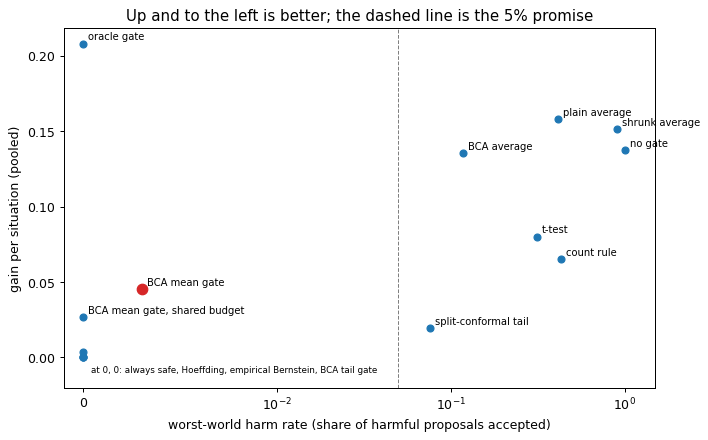

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))
near_zero = []
for g in GATES:
    harm = harm_by_world(DEC[g], EVAL_SEEDS).max()
    gain = gain_by_world(DEC[g], EVAL_SEEDS).mean()
    star = g == "BCA mean gate"
    ax.scatter(harm, gain, s=70 if star else 30, color="C3" if star else "C0", zorder=3)
    if harm < 0.002 and gain < 0.01:
        near_zero.append(g)
    else:
        ax.annotate(g, (harm, gain), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.annotate("at 0, 0: " + ", ".join(near_zero), (0, 0), fontsize=7, xytext=(6, -12), textcoords="offset points")
ax.axvline(DELTA, color="grey", ls="--", lw=0.8)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlim(-0.001, 1.5); ax.set_ylim(bottom=-0.02)
ax.set_xlabel("worst-world harm rate (share of harmful proposals accepted)")
ax.set_ylabel("gain per situation (pooled)")
ax.set_title("Up and to the left is better; the dashed line is the 5% promise")
fig.tight_layout(); plt.show()

**Verdicts.**

In [29]:
ev = EVAL_SEEDS
allow = allowance(ev)
verdict = lambda alive: "ALIVE" if alive else "SHELVED"

h1 = harm_by_world(DEC["BCA mean gate"], ev)
print(f"Claim 1, BCA's mean gate keeps its promise: worst harm rate {h1.max():.3f}; "
      f"worlds above their allowance: {(h1 > allow).sum()} -> {verdict(not (h1 > allow).any())}")

ga = {g: good_accepted(DEC[g], ev) for g in ("BCA mean gate", "Hoeffding", "empirical Bernstein")}
c2 = ga["BCA mean gate"] - max(ga["Hoeffding"], ga["empirical Bernstein"]) >= 0.05
print(f"Claim 2, tightest guaranteed mean gate: good proposals accepted {ga['BCA mean gate']:.1%} against "
      f"Hoeffding {ga['Hoeffding']:.1%} and empirical Bernstein {ga['empirical Bernstein']:.1%} -> {verdict(c2)}")

ht = harm_by_world(DEC["t-test"], ev)
c3 = bool((ht[1] > allow[1]).any())
print(f"Claim 3, the t-test is unsafe with rare disasters: worst rare-disaster harm rate {ht[1].max():.3f} "
      f"-> {verdict(c3)}")

crowded = np.zeros((len(SHAPES), len(GOOD_SHARES), len(CANDIDATES)), bool)
crowded[:, :2, 2:] = True
gc = {g: gain_by_world(DEC[g], ev)[crowded].mean() for g in ("BCA mean gate", "plain average", "shrunk average")}
c4 = gc["BCA mean gate"] > max(gc["plain average"], gc["shrunk average"])
print(f"Claim 4, crowded worlds: gain {gc['BCA mean gate']:.4f} against plain average {gc['plain average']:.4f} "
      f"and shrunk average {gc['shrunk average']:.4f} -> {verdict(c4)}")

TUNABLE = {"plain average": MARGINS, "shrunk average": MARGINS, "BCA average": MARGINS, "t-test": LEVELS,
           "Hoeffding": LEVELS, "empirical Bernstein": LEVELS, "BCA mean gate": LEVELS,
           "BCA tail gate": TAIL_SHARES, "split-conformal tail": TAIL_SHARES, "count rule": COUNTS}
FRONTIER, TUNED = {}, {}
for g, grid in TUNABLE.items():
    points = []
    for k in grid:
        d = accept(g, k)
        points.append((k, harm_by_world(d, TUNE_SEEDS).max(), gain_by_world(d, TUNE_SEEDS).mean(), d))
    FRONTIER[g] = points
    qualified = [p for p in points if p[1] <= DELTA]
    if qualified:
        k, _, tune_gain, d = max(qualified, key=lambda p: p[2])
        TUNED[g] = (k, tune_gain, gain_by_world(d, ev).mean(), harm_by_world(d, ev).max())
    else:
        TUNED[g] = (None, 0.0, 0.0, 0.0)
best_rival = max((g for g in TUNED if g != "BCA mean gate"), key=lambda g: TUNED[g][2])
c5 = TUNED["BCA mean gate"][2] > TUNED[best_rival][2]
print(f"Claim 5, at equal harm: tuned BCA mean gate gains {TUNED['BCA mean gate'][2]:.4f}; best tuned rival "
      f"{best_rival} gains {TUNED[best_rival][2]:.4f} -> {verdict(c5)}")

gb = gain_by_world(DEC["BCA mean gate, shared budget"], ev).mean()
gm = gain_by_world(DEC["BCA mean gate"], ev).mean()
fs = false_share_by_world(DEC["BCA mean gate, shared budget"], ev)
c6 = gb > gm and fs.max() <= 0.12
print(f"Claim 6, shared 10% harm budget: gain {gb:.4f} against {gm:.4f} deciding alone; worst average harmful "
      f"share of acceptances {fs.max():.3f} -> {verdict(c6)}")

Claim 1, BCA's mean gate keeps its promise: worst harm rate 0.003; worlds above their allowance: 0 -> ALIVE
Claim 2, tightest guaranteed mean gate: good proposals accepted 17.4% against Hoeffding 0.0% and empirical Bernstein 0.0% -> ALIVE
Claim 3, the t-test is unsafe with rare disasters: worst rare-disaster harm rate 0.313 -> ALIVE
Claim 4, crowded worlds: gain 0.0567 against plain average 0.1829 and shrunk average 0.1625 -> SHELVED
Claim 5, at equal harm: tuned BCA mean gate gains 0.0845; best tuned rival BCA average gains 0.0400 -> ALIVE
Claim 6, shared 10% harm budget: gain 0.0270 against 0.0453 deciding alone; worst average harmful share of acceptances 0.000 -> SHELVED


### Equal harm: what each gate earns once tuned to the same safety level

Each gate has one knob: a margin for the averages, a confidence level for the bounds, a share for the tail gates, and a count for the count rule. The chart shows every setting on seeds 0–99: how often the gate accepted a harmful proposal in its worst world (left–right), and how much it gained (up–down). The table then takes each gate's best setting with at most 5% harm in every world, and scores it on the fresh seeds 100–199.

gate                      chosen knob  gain, seeds 0-99  gain, seeds 100-199  worst harm, 100-199
BCA mean gate                     0.2            0.0864               0.0845                 2.3%
BCA average                       0.5            0.0410               0.0400                 3.8%
shrunk average                    0.5            0.0165               0.0187                 1.6%
Hoeffding                         0.5            0.0167               0.0174                 0.1%
BCA tail gate                     0.2            0.0187               0.0172                 2.9%
plain average                     1.5            0.0061               0.0070                 0.8%
empirical Bernstein               0.5            0.0061               0.0061                 0.0%
split-conformal tail             0.05            0.0064               0.0056                 0.3%
count rule                        100            0.0001               0.0003                 0.2%
t-test              

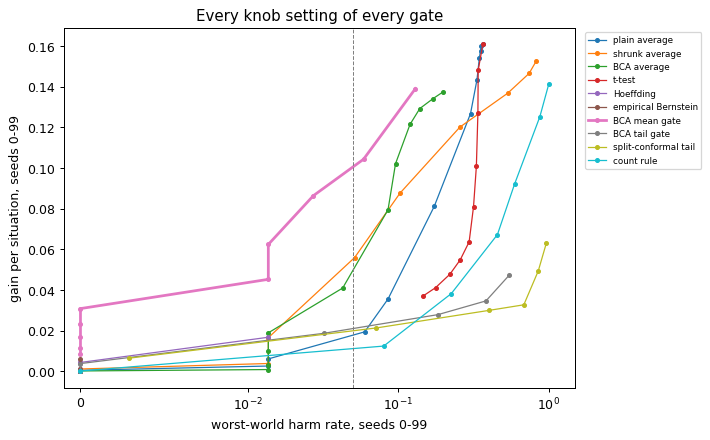

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, (g, points) in enumerate(FRONTIER.items()):
    xs, ys = [p[1] for p in points], [p[2] for p in points]
    ax.plot(xs, ys, marker="o", ms=3, lw=2.2 if g == "BCA mean gate" else 1, color=f"C{i}", label=g)
ax.axvline(DELTA, color="grey", ls="--", lw=0.8)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlim(-0.001, 1.5)
ax.set_xlabel("worst-world harm rate, seeds 0-99")
ax.set_ylabel("gain per situation, seeds 0-99")
ax.set_title("Every knob setting of every gate")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

print(f"{'gate':24}{'chosen knob':>13}{'gain, seeds 0-99':>18}{'gain, seeds 100-199':>21}{'worst harm, 100-199':>21}")
for g, (k, tune_gain, eval_gain, eval_harm) in sorted(TUNED.items(), key=lambda kv: -kv[1][2]):
    print(f"{g:24}{'none' if k is None else str(k):>13}{tune_gain:18.4f}{eval_gain:21.4f}{eval_harm:21.1%}")

**Where each gate earns its gain:** by outcome shape, by number of candidates, worst harm by shape, and the share of good proposals accepted by number of held-out tries.

In [31]:
key = ["plain average", "shrunk average", "t-test", "Hoeffding", "empirical Bernstein", "BCA mean gate",
       "BCA tail gate", "BCA mean gate, shared budget", "oracle gate"]
print("Gain per situation by outcome shape (seeds 100-199, pooled over the other two factors)")
print(f"{'gate':31}" + "".join(f"{s:>15}" for s in SHAPES))
for g in key:
    print(f"{g:31}" + "".join(f"{v:15.4f}" for v in gain_by_world(DEC[g], ev).mean(axis=(1, 2))))

print("\nGain per situation by number of candidates (seeds 100-199)")
print(f"{'gate':31}" + "".join(f"{m:>10}" for m in CANDIDATES))
for g in key:
    print(f"{g:31}" + "".join(f"{v:10.4f}" for v in gain_by_world(DEC[g], ev).mean(axis=(0, 1))))

print("\nHarm rate by outcome shape, worst over the other factors (seeds 100-199)")
print(f"{'gate':31}" + "".join(f"{s:>15}" for s in SHAPES))
for g in key:
    print(f"{g:31}" + "".join(f"{v:15.1%}" for v in harm_by_world(DEC[g], ev).max(axis=(1, 2))))

bins = [(5, 9), (10, 19), (20, 39), (40, 69), (70, 100)]
print("\nShare of good proposals accepted, by number of held-out tries (seeds 100-199)")
print(f"{'gate':31}" + "".join(f"{f'{a}-{b}':>9}" for a, b in bins))
for g in key:
    row = []
    for a, b in bins:
        sel = GOOD[ev] & (NTRY[ev] >= a) & (NTRY[ev] <= b)
        row.append((DEC[g][ev] & sel).sum() / max(sel.sum(), 1))
    print(f"{g:31}" + "".join(f"{v:9.0%}" for v in row))

Gain per situation by outcome shape (seeds 100-199, pooled over the other two factors)
gate                                    steady  rare disaster   rare jackpot
plain average                           0.1755         0.0951         0.2038
shrunk average                          0.1616         0.0765         0.2156
t-test                                  0.0993         0.0843         0.0567
Hoeffding                               0.0000         0.0000         0.0001
empirical Bernstein                     0.0000         0.0000         0.0000
BCA mean gate                           0.0540         0.0138         0.0681
BCA tail gate                           0.0000         0.0099         0.0000
BCA mean gate, shared budget            0.0370         0.0032         0.0407
oracle gate                             0.1987         0.1565         0.2690

Gain per situation by number of candidates (seeds 100-199)
gate                                    1         3        10        30
plain avera

**Information only (written after the run; not part of the claims).** Two questions the claims did not ask:
1. Does the winner depend on how strict the safety level is? Each gate is tuned on seeds 0–99 to its best setting under a cap on worst-world harm, then scored on seeds 100–199. A wider cap allows more harm.
2. Does any gate lose return, meaning it does worse than always staying safe in some world?

In [32]:
CAPS = (0.01, 0.02, 0.05, 0.1, 0.2, 1.0)
print("1. Gain per situation on seeds 100-199, after tuning on seeds 0-99 to each cap on worst-world harm")
print(f"{'gate':22}" + "".join(f"{f'cap {c:.0%}':>10}" for c in CAPS))
held = True
for g, points in FRONTIER.items():
    cells = []
    for cap in CAPS:
        ok = [p for p in points if p[1] <= cap]
        if not ok:
            cells.append(f"{'none':>10}")
            continue
        d = max(ok, key=lambda p: p[2])[3]
        held &= bool(harm_by_world(d, ev).max() <= cap)
        cells.append(f"{gain_by_world(d, ev).mean():10.3f}")
    print(f"{g:22}" + "".join(cells))
print("On seeds 100-199, every tuned gate stayed within its cap:", held)

print("\n2. Worlds (of 36) where each gate loses return at its stated setting, seeds 100-199")
print(f"{'gate':31}{'worlds below 0':>16}{'lowest world gain':>19}")
for g in GATES:
    gw = gain_by_world(DEC[g], ev)
    print(f"{g:31}{(gw < 0).sum():16d}{gw.min():19.4f}")

print("\nThe hardest worlds: rare disasters and 10% good candidates. Gain by number of candidates, seeds 100-199")
print(f"{'gate':31}" + "".join(f"{m:>10}" for m in CANDIDATES))
for g in ("no gate", "plain average", "t-test", "shrunk average", "BCA mean gate", "BCA average", "oracle gate"):
    print(f"{g:31}" + "".join(f"{v:10.4f}" for v in gain_by_world(DEC[g], ev)[1, 0]))

1. Gain per situation on seeds 100-199, after tuning on seeds 0-99 to each cap on worst-world harm
gate                      cap 1%    cap 2%    cap 5%   cap 10%   cap 20%  cap 100%
plain average              0.001     0.007     0.007     0.036     0.078     0.158
shrunk average             0.001     0.019     0.019     0.056     0.087     0.151
BCA average                0.000     0.021     0.040     0.098     0.136     0.136
t-test                      none      none      none      none     0.040     0.158
Hoeffding                  0.005     0.017     0.017     0.017     0.017     0.017
empirical Bernstein        0.006     0.006     0.006     0.006     0.006     0.006
BCA mean gate              0.030     0.061     0.084     0.103     0.137     0.137
BCA tail gate              0.003     0.003     0.017     0.017     0.027     0.046
split-conformal tail       0.006     0.006     0.006     0.019     0.019     0.062
count rule                 0.000     0.000     0.000     0.011     0.01

**Checks.** Any failure stops the notebook.

In [33]:
# 1. The exact average gains match simulation, sit inside the stated range, and have the intended sign.
rng = np.random.default_rng([ROOT_SEED, 999])
for shape in SHAPES:
    good = rng.random(6) < 0.5
    cand = candidates(shape, good, rng.random(6), rng.random(6))
    sim = tries(shape, cand, rng.random((6, 200_000)), rng.standard_normal((6, 200_000)))
    se = sim.std(axis=1) / math.sqrt(sim.shape[1])
    assert np.all(np.abs(sim.mean(axis=1) - cand["mean"]) < 5 * se), shape
    assert np.all((cand["mean"] > 0) == good), shape
    assert sim.min() >= FLOOR[shape] and sim.max() <= CEILING[shape], shape
# 2. The mean gate's sampler matches the exact answer for identical tries: with n tries of gain g and floor a,
#    the chance that a weighted average is below 0 is (-a / (g - a)) ** n.
w = np.random.default_rng([ROOT_SEED, 998]).standard_exponential((DRAWS, N_MAX + 1))
for n_, g_, a_ in ((10, 0.35, -1.0), (29, 0.11, -1.0), (29, 0.4, -10.0), (100, 0.03, -1.0)):
    estimate = ((w[:, :n_] * g_).sum(axis=1) + w[:, N_MAX] * a_ < 0).mean()
    exact = (-a_ / (g_ - a_)) ** n_
    assert abs(estimate - exact) < 4 * math.sqrt(exact * (1 - exact) / DRAWS), (n_, g_, a_, estimate, exact)
# 3. Student's t quantiles match published tables.
for level, df, want in ((0.05, 4, 2.1318), (0.05, 9, 1.8331), (0.01, 29, 2.4620), (0.005, 99, 2.6264)):
    assert abs(t_upper(level, df) - want) < 1e-3, (level, df)
# 4. BCA's tail gate cannot accept anything below 29 tries.
assert allowed_below(28, TAIL) == -1 and allowed_below(29, TAIL) == 0
# 5. Gates accept only real proposals, and none gains more than the oracle gate in any world.
oracle_by_world = gain_by_world(DEC["oracle gate"], EVAL_SEEDS)
for g, d in DEC.items():
    assert not (d & ~EXISTS).any(), g
    assert np.all(gain_by_world(d, EVAL_SEEDS) <= oracle_by_world + 1e-12), g
# 6. The critic never sees held-out tries: rerunning seed 0 with different held-out tries changes no proposal.
same, flipped = run_seed(0), run_seed(0, flip_held=True)
for f in ("exists", "mu", "n", "best"):
    assert np.array_equal(same[f], flipped[f]), f
assert not np.array_equal(same["mean"], flipped["mean"])
print("All checks passed. Notebook seconds:", round(time.perf_counter() - START, 1))

All checks passed. Notebook seconds: 22.8


## What Part 3 found

| Claim | Result | Verdict |
|---|---|---|
| 1. The mean gate keeps its promise | worst harm rate 0.3% in any world | alive |
| 2. It is the tightest guaranteed mean gate | 17.4% of good proposals accepted, against 0% for Hoeffding and empirical Bernstein | alive |
| 3. The t-test is unsafe with rare disasters | up to 31.3% of harmful proposals accepted | alive |
| 4. In crowded worlds it beats simple averaging | 0.057 per situation, against 0.183 (plain) and 0.163 (shrunk) | shelved |
| 5. At equal harm it earns the most | 0.084, against 0.040 for the next gate (BCA's cautious average) | alive |
| 6. Deciding all situations together earns more | 0.027, against 0.045 deciding each alone | shelved |

- **The promise held, with room to spare.** At its stated 5% level, the mean gate accepted at most 0.3% of harmful proposals in any world. That also shows it is cautious in these worlds.
- **It is far tighter than the classic guaranteed bounds.** Hoeffding and empirical Bernstein accepted almost none of the good proposals: with a wide range such as −8 to 3, they need far more tries.
- **The t-test, the usual shortcut, fails when disasters are rare.** Many small samples contain no disaster, so the t-test sees a steady small gain and accepts. In one rare-disaster world it accepted 31% of harmful proposals, and no t-test setting stayed within 5% harm in every world.
- **At equal harm, the mean gate earned the most.** Tuned to at most 5% harm in every world, it earned 0.084 per situation, at a 20% setting with a worst harm rate of 2.3%. Next came BCA's cautious average (0.040), the shrunk average (0.019), Hoeffding (0.017) and BCA's tail gate (0.017). It also earned the most at every harm cap tried, from 1% to 20%.
- **It did not beat simple averaging where many candidates compete (claim 4, shelved).**
  - *The idea:* where many candidates compete and few are good, the critic is often fooled by a lucky candidate, so a cautious gate should earn more than simply checking the held-out average.
  - *What we tested (and the kill rule):* pooled gain over the 12 crowded worlds (10 or 30 candidates, 10% or 30% good); shelved unless the mean gate earned more than both the plain and the shrunk average.
  - *What happened:* 0.057 per situation, against 0.183 and 0.163.
  - *Why:* the held-out tries are fresh, so their average is an honest estimate of a proposal's gain, however lucky the critic's training tries were. After that, extra caution mostly turns good candidates away. With 5–9, 10–19 and 20–39 tries, the mean gate accepted 1%, 5% and 17% of good proposals; the plain average accepted 71%, 80% and 89%.
- **Deciding all situations together earned less (claim 6, shelved).**
  - *The idea:* deciding the 20 situations together, with a shared budget of 10% harmful acceptances, should let more good candidates through than deciding each one alone at 5%.
  - *What we tested (and the kill rule):* pooled gain against the mean gate deciding each situation alone; shelved unless it earned more, with at most 12% harmful acceptances on average in every world.
  - *What happened:* 0.027 per situation, against 0.045. Harm was not the problem: in every world, under 0.1% of its acceptances were harmful on average.
  - *Why:* deciding together lets more through only when many situations look clearly good at once. Here few proposals pass at all, and then the shared bar is stricter than 5% per situation.
- **A lead, not a claim.** BCA's cautious average, (sum of tries + floor) ÷ (tries + 1), has no knob. It earned 86% of the plain average's return and never lost return in any world. In the hardest worlds (rare disasters, 10% good candidates), the plain average and the t-test lost return; there it earned the most of any real gate, 0.008 to 0.048 per situation.

**The insight.** When the policy must stay safe, BCA's mean gate was the best gate we found. It uses the same random weights as BCA's tail gate, but asks about the average instead of the 90% share. When no safety level is required and the held-out evidence is fresh, plain averaging earns more, because caution then only costs return.

---
# Part 4. Do BCA's weights help when the log and deployment visit different states?

*Pre-registered. Original notebook: `bca_weights_toy.ipynb`. Kill rules fingerprint `e32e04d7…f44e`.*

**The question.** With equal weights, BCA is a textbook test (Part 2). Its one part that is not textbook is its **weights**: production BCA can reweight held-out tries so that they speak for the states the policy will actually meet. When the tries come from a different mix of states than deployment, do the weights keep BCA's promises? And do they use the evidence better than the simple valid alternatives?

**The setup.**
- A policy wants to **deviate**: take a risky action (think full throttle) instead of a well-logged **fallback**. It decides once for a whole region of states: deviate everywhere in the region, or fall back everywhere.
- The region has five **conditions**, from mild (0) to harsh (4). The log's held-out tries of the deviation came mostly from mild conditions; deployment may meet harsh conditions more often. The difference between the two mixes is the **shift**.
- Each try's **gain** over the fallback is usually small and positive (about 0.5), but sometimes a **disaster** (−4). How often disasters happen depends on the condition.
- A gate reads the held-out tries and decides. Both promises are tested: the **tail promise**, as in Part 2, and the **mean promise**, as in Part 3.
- **Weights.** A try's weight = (its condition's share at deployment) ÷ (its condition's share in the log). A try from a condition that deployment meets often, but the log rarely saw, counts for more. Here the weights are known exactly.

**Words used in this part.**
- **Deviation rate:** the share of seeds in which a gate deviates. In an unsafe or harmful world, it is how often the gate breaks its promise.
- **Effective number of tries:** how many equally weighted tries the weighted ones are worth, (sum of weights)² ÷ (sum of squared weights). A stronger shift makes it smaller.
- **Gain:** the true average gain at deployment if the gate deviates, and 0 if it falls back. **Pooled gain** averages it over all worlds.

### The worlds

| Factor | Settings |
|---|---|
| Where harm sits | everywhere alike; in harsh conditions; in mild conditions |
| Disaster chance at deployment (the **rung**) | 0, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15, 0.20 |
| Shift | none; moderate; strong |
| Held-out tries | 30, 60, 120, 240 |

That makes 288 worlds, each run on 800 seeds.

- **The rung fixes the truth at deployment.** Rungs 0.10 and above are unsafe; rungs 0.12 and above are harmful. At 0.10 the deviation is unsafe but still good on average.
- **Where harm sits, and the shift, change only what the log shows.** When harm sits in harsh conditions and deployment meets them more often, the log makes the deviation look safer than it is. When harm sits in mild conditions, the log makes it look worse.

| Condition | 0 (mild) | 1 | 2 | 3 | 4 (harsh) |
|---|---|---|---|---|---|
| Share among the log's tries | 35% | 25% | 20% | 12% | 8% |
| Share at deployment, moderate shift | 15% | 20% | 25% | 20% | 20% |
| Share at deployment, strong shift | 5% | 10% | 15% | 30% | 40% |

All worlds share the same random numbers, so differences between worlds come from the worlds, not from luck.

### The gates

| Gate | Deviates when | Promise |
|---|---|---|
| never deviate, always deviate | never; always | references |
| BCA tail, unweighted | BCA with equal weights (in exact form) is 95% sure that at least 90% of tries beat the fallback | tail, but for the log's mix |
| **BCA tail, weighted** | the same, with BCA's weights and its extra worst-case weight, as built in `calibration/wbcp.py` (1,000 draws) | tail, at deployment: claim 2 tests it |
| weighted split conformal | the weighted 10% cutoff of the tries beats the fallback ([Tibshirani and others, 2019](https://ar5iv.labs.arxiv.org/html/1904.06019)) | tail, at deployment, only on average over data sets |
| rejection-sampled exact | each try is kept with chance weight ÷ largest weight, then the exact test runs on the kept tries (Park and others, 2022) | tail, at deployment |
| stratified exact | an exact bound per condition (at 1% each), combined with the deployment mix | tail, at deployment |
| BCA mean, unweighted | BCA's mean gate on all tries, with floor −4 (10,000 draws) | mean, but for the log's mix |
| **BCA mean, weighted** | the same, with weights on the tries and the average deployment weight on the extra floor weight | mean, at deployment: claim 5 tests it |
| rejection-sampled BCA mean | BCA's mean gate on the kept tries | mean, at deployment |
| weighted t-test | the weighted average, minus a t-test margin with the usual weighted standard error, is above 0 | mean, roughly, if outcomes are bell-shaped |
| weighted average | the weighted average gain is above 0 | none |
| plain average | the plain average gain is above 0 | none |
| oracle | the deviation is truly good on average at deployment | scoring reference |

The two bold gates are under test. Rejection sampling and the stratified bound are the simple ways to keep a valid promise under shift, and both throw evidence away. No proof covers the weighted mean gate; it is the natural weighted version of Part 3's mean gate.

### What would shelve each claim

The binding version is the kill-rule text in the code below. A world's **allowance** on a 5% rate is 5% plus three standard errors over 800 seeds, about 7.3%.
1. **Ignoring the shift breaks BCA's tail promise.** Shelved if the unweighted tail gate stays within the allowance in every unsafe world.
2. **With weights, BCA's tail gate as built keeps its promise.** Shelved if it is above the allowance in any unsafe world.
3. **The weights use shifted evidence better than the simple valid alternatives.** Shelved unless, pooled over the safe shifted worlds, the weighted tail gate deviates at least 5 points more often than both rejection sampling and the stratified bound.
4. **Weighted BCA's promise holds for the data in hand, unlike weighted split conformal's.** Shelved unless weighted split conformal's worst unsafe-world rate is at least 5 points above weighted BCA's.
5. **With weights, BCA's mean gate keeps its promise.** Shelved if it is above the allowance in any harmful world.
6. **At equal harm, the weighted mean gate earns the most.** On seeds 0–399, each gate takes its best setting among those with at most 5% in every harmful world. Shelved if any other tuned gate earns at least as much on seeds 400–799.

In [34]:
import math, os, sys, time, hashlib
from fractions import Fraction
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt

START = time.perf_counter()
ROOT_SEED, STREAM = 20261014, 43
N_SEEDS = 800
TUNE_SEEDS, EVAL_SEEDS = np.arange(0, 400), np.arange(400, 800)
SHIFTS = ("none", "moderate", "strong")
LOG_PCT = np.array([35, 25, 20, 12, 8])                          # conditions 0 (mild) to 4 (harsh), in percent
DEPLOY_PCT = {"none": LOG_PCT, "moderate": np.array([15, 20, 25, 20, 20]), "strong": np.array([5, 10, 15, 30, 40])}
PROFILES = ("harm everywhere alike", "harm in harsh conditions", "harm in mild conditions")
STEEPNESS = 0.6                                                  # how sharply harm rises or falls across conditions
RUNGS = (0.0, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15, 0.20)          # disaster chance at deployment
SIZES = (30, 60, 120, 240)                                       # held-out tries the gate reads
N_MAX = max(SIZES)
CENTER, SPREAD, LO, HI = 0.5, 0.2, -1.0, 2.0                     # usual gain: clip(0.5 + 0.2 Z, -1, 2)
DISASTER = FLOOR = -4.0                                          # a disaster's gain, also the worst possible gain
TAIL, CONFIDENCE, DELTA = 0.10, 0.95, 0.05
TAIL_DRAWS, MEAN_DRAWS = 1000, 10_000                            # 1,000 as built for the tail gate
TAIL_SHARES = (0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05)              # knob grids for claim 6
LEVELS = (0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.001)
MARGINS = (0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.75, 1.0)

LOG_MIX = LOG_PCT / 100
DEPLOY_MIX = {s: DEPLOY_PCT[s] / 100 for s in SHIFTS}
STRATA_LEVEL = DELTA / LOG_MIX.size
WEIGHT = np.array([DEPLOY_PCT[s] / LOG_PCT for s in SHIFTS])     # (shift, condition): deployment share / log share
WBAR = np.array([float(sum(Fraction(int(d) ** 2, int(l)) for d, l in zip(DEPLOY_PCT[s], LOG_PCT)) / 100)
                 for s in SHIFTS])                               # average weight at deployment (BCA's test mass)
WMAX = WEIGHT.max(axis=1)
assert all(DEPLOY_PCT[s].sum() == 100 for s in SHIFTS) and TAIL in TAIL_SHARES and DELTA in LEVELS

**How much evidence each tail gate needs.** Shift costs every valid gate evidence; the question is how much. The next cell shows how many held-out tries each tail gate needs before it can say yes at all, even when every try beats the fallback. (Unweighted BCA needs 29 in every case, but under shift it answers for the wrong mix.)

In [35]:
def tries_needed_weighted(si):
    """About how many tries weighted BCA's tail gate needs to say yes when every try beats the fallback."""
    c = TAIL / ((1 - TAIL) * WBAR[si])
    return math.ceil(math.log(1 / (1 - CONFIDENCE)) / (LOG_MIX @ np.log1p(c * WEIGHT[si])))

def tries_needed_stratified(si):
    """About how many tries the stratified exact gate needs, with condition counts at their expected values."""
    for n in range(1, 5000):
        bound = DEPLOY_MIX[SHIFTS[si]] @ (1 - STRATA_LEVEL ** (1 / (n * LOG_MIX)))
        if bound <= TAIL:
            return n
    return math.inf

print("shift      effective tries   tries kept by       tries needed to say yes at all (about)")
print("           per try           rejection           weighted BCA   rejection-sampled exact   stratified exact")
for si, shift in enumerate(SHIFTS):
    print(f"{shift:10}{1 / WBAR[si]:>11.2f}{1 / WMAX[si]:>17.2f}{tries_needed_weighted(si):>22d}"
          f"{math.ceil(29 * WMAX[si]):>20d}{tries_needed_stratified(si):>23d}")

shift      effective tries   tries kept by       tries needed to say yes at all (about)
           per try           rejection           weighted BCA   rejection-sampled exact   stratified exact
none             1.00             1.00                    29                  29                    216
moderate         0.73             0.40                    39                  73                    287
strong           0.34             0.20                    83                 145                    382


In [36]:
def Phi(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def phi(x):
    return math.exp(-0.5 * x * x) / math.sqrt(2 * math.pi)

def clipped_mean(center, spread, lo, hi):
    """Exact average of clip(center + spread * Z, lo, hi) for a standard normal Z."""
    a, b = (lo - center) / spread, (hi - center) / spread
    return lo * Phi(a) + hi * (1 - Phi(b)) + center * (Phi(b) - Phi(a)) + spread * (phi(a) - phi(b))

PROFILE_SHAPE = {"harm everywhere alike": np.ones(LOG_MIX.size),
                 "harm in harsh conditions": np.exp(STEEPNESS * (np.arange(LOG_MIX.size) - 2)),
                 "harm in mild conditions": np.exp(-STEEPNESS * (np.arange(LOG_MIX.size) - 2))}

def disaster_chances(profile, rung, shift):
    """Disaster chance in each condition, scaled so that deployment's overall chance is the rung."""
    shape = PROFILE_SHAPE[profile]
    return rung * shape / (DEPLOY_MIX[shift] @ shape)

P_K = np.array([[[disaster_chances(p, r, s) for s in SHIFTS] for r in RUNGS] for p in PROFILES])  # (profile, rung, shift, condition)
USUAL_MEAN = clipped_mean(CENTER, SPREAD, LO, HI)
USUAL_BELOW = Phi(-CENTER / SPREAD)                             # chance that a usual gain is below 0
RUNG = np.array(RUNGS)
MU = (1 - RUNG) * USUAL_MEAN + RUNG * DISASTER                  # true average gain at deployment, by rung
BAD = RUNG + (1 - RUNG) * USUAL_BELOW                           # true share of outcomes below the fallback at deployment
UNSAFE, HARMFUL = BAD > TAIL, MU < 0
WORLD = (len(PROFILES), len(RUNGS), len(SHIFTS), len(SIZES))

@lru_cache(maxsize=None)
def t_upper(level, df):
    """t with P(T > t) = level for Student's t with df degrees of freedom (Simpson's rule and bisection)."""
    c = math.exp(math.lgamma((df + 1) / 2) - math.lgamma(df / 2)) / math.sqrt(df * math.pi)
    w = np.ones(2001)
    w[1:-1:2], w[2:-1:2] = 4, 2
    def tail(t):
        x = np.linspace(0.0, t, 2001)
        return 0.5 - t / 6000 * (w * c * (1 + x * x / df) ** (-(df + 1) / 2)).sum()
    lo, hi = 0.0, 1.0
    while tail(hi) > level:
        hi *= 2
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if tail(mid) > level else (lo, mid)
    return hi

@lru_cache(maxsize=None)
def allowed_below(n, share, confidence=CONFIDENCE):
    """BCA's equal-weight tail gate in exact form: the most tries that may fall below the fallback, or -1 if none may."""
    cdf, best = 0.0, -1
    for x in range(n + 1):
        cdf += math.exp(math.lgamma(n + 1) - math.lgamma(x + 1) - math.lgamma(n - x + 1)
                        + x * math.log(share) + (n - x) * math.log1p(-share))
        if cdf > 1 - confidence:
            break
        best = x
    return best

def by_count(fn):
    """fn evaluated at every possible number of tries 0..N_MAX, for lookups by count."""
    return np.array([fn(k) for k in range(N_MAX + 1)])

LOGFACT = np.concatenate([[0.0], np.cumsum(np.log(np.arange(1, N_MAX + 1)))])

def cp_upper(b, n, level):
    """Clopper-Pearson upper bounds for arrays of (bad, tries): the largest p with P(Binomial(n, p) <= b) >= level."""
    b, n = np.asarray(b, dtype=int), np.asarray(n, dtype=int)
    out = np.ones(b.shape)
    todo = b < n
    bb, nn = b[todo], n[todo]
    x = np.arange(N_MAX + 1)[None, :]
    inside = x <= bb[:, None]
    logc = LOGFACT[nn][:, None] - LOGFACT[x] - LOGFACT[np.clip(nn[:, None] - x, 0, None)]
    lo, hi = np.zeros(bb.size), np.ones(bb.size)
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        logpmf = logc + x * np.log(mid)[:, None] + (nn[:, None] - x) * np.log1p(-mid)[:, None]
        cdf = np.exp(np.where(inside, logpmf, -np.inf)).sum(axis=1)
        up = cdf >= level
        lo, hi = np.where(up, mid, lo), np.where(up, hi, mid)
    out[todo] = lo
    return out

def limit(level):
    return math.floor(Fraction(str(level)) * MEAN_DRAWS)

In [37]:
KILL_RULES = """
Written before the first run of this notebook. Not to be changed after seeing the results.

Words used. A world is one combination of where harm sits (3 profiles), the disaster chance at deployment (the
rung: 0, 0.02, 0.05, 0.08, 0.10, 0.12, 0.15 or 0.20), how far deployment's mix of conditions differs from the
log's (no, moderate or strong shift) and how many held-out tries the gate reads (30, 60, 120 or 240), so there
are 288 worlds. A world is unsafe when more than 10% of the deviation's outcomes at deployment fall below the
fallback, harmful when its true average gain over the fallback at deployment is below zero, and safe when it is
not unsafe. Shifted worlds have a moderate or strong shift. A gate's deviation rate in a world is the share of
seeds in which it deviates. Unless a claim says otherwise, results use all 800 seeds and each gate's stated
setting. A world's allowance on a 5% rate is 0.05 + 3 * sqrt(0.05 * 0.95 / 800), about 0.073. Pooled gain is
a gate's deviation rate times the true average gain at deployment, averaged over all 288 worlds with equal
weight.

Claim 1. Ignoring the shift breaks BCA's tail promise. Shelved if the unweighted BCA tail gate's deviation rate
is within the allowance in every unsafe world.

Claim 2. With weights, BCA's tail gate as built keeps its promise under shift. Shelved if its deviation rate is
above the allowance in any unsafe world.

Claim 3. BCA's weights use shifted evidence better than the simple valid alternatives. Shelved unless, pooled
over the safe shifted worlds, the weighted BCA tail gate's deviation rate is at least 0.05 above the
rejection-sampled exact test's and at least 0.05 above the stratified exact test's.

Claim 4. Weighted BCA's promise holds for the data in hand, unlike weighted split conformal's. Shelved unless
weighted split conformal's highest deviation rate over the unsafe worlds is at least 0.05 above the weighted BCA
tail gate's highest.

Claim 5. With weights, BCA's mean gate keeps its promise under shift. Shelved if its deviation rate is above the
allowance in any harmful world.

Claim 6. At equal harm, the weighted BCA mean gate earns the most. On seeds 0-399, each tunable gate takes the
setting from its fixed grid with the highest pooled gain among settings whose deviation rate is at most 0.05 in
every harmful world; a gate with no such setting never deviates. Shelved if, on seeds 400-799, any other tuned
gate's pooled gain is at least the tuned weighted BCA mean gate's.
"""
print("Kill rules fingerprint (SHA-256):", hashlib.sha256(KILL_RULES.encode()).hexdigest())

Kill rules fingerprint (SHA-256): e32e04d79b52e3a234e2576ef7cddf9c7b667436315b58330fe827b2dafff44e


**The run.** For each seed, the next cell draws the log's held-out tries once (their conditions, disaster coins, usual gains and rejection-sampling coins) and BCA's random weightings once, and reuses them in every world. It takes most of this notebook's running time. The cell after it turns each gate into decisions.

In [38]:
FIELDS = ("bad", "wgood", "wsum", "wsq", "kept", "kept_bad", "neg_w", "neg_u", "neg_r", "m_w", "se_w", "m_u")
SHIFT_OF = np.broadcast_to(np.arange(len(SHIFTS)), WORLD[:3]).reshape(-1)    # shift of each flattened world

def run_seed(seed):
    rng = np.random.default_rng([ROOT_SEED, STREAM, seed])
    cond = rng.choice(LOG_MIX.size, N_MAX, p=LOG_MIX)            # each try's condition, from the log's mix
    u, v = rng.random((2, N_MAX))                                 # disaster coin; rejection-sampling coin
    z = rng.standard_normal(N_MAX)
    e = rng.standard_exponential((MEAN_DRAWS, N_MAX + 1))         # BCA's random weights; the last column is the extra one
    gain = np.where(u < P_K[..., cond], DISASTER, np.clip(CENTER + SPREAD * z, LO, HI))   # (profile, rung, shift, try)
    good = gain >= 0
    w = WEIGHT[:, cond]                                           # (shift, try)
    keep = v < w / WMAX[:, None]
    rec = {f: np.zeros(WORLD) for f in FIELDS}
    rec["cross"] = np.zeros((len(TAIL_SHARES),) + WORLD)
    rec["n_k"] = np.zeros(WORLD + (LOG_MIX.size,))
    rec["b_k"] = np.zeros(WORLD + (LOG_MIX.size,))
    for zi, n in enumerate(SIZES):
        g, ok, kn = gain[..., :n], good[..., :n], keep[:, :n]
        W = w[None, None, :, :n]                                  # broadcast over profile and rung
        flat = lambda a: np.broadcast_to(a, g.shape).reshape(-1, n).T     # (tries, worlds)
        rec["bad"][..., zi] = (~ok).sum(-1)
        rec["wgood"][..., zi] = (W * ok).sum(-1)
        rec["wsum"][..., zi] = W.sum(-1)
        rec["wsq"][..., zi] = (W ** 2).sum(-1)
        rec["kept"][..., zi] = kn.sum(-1)[None, None]
        rec["kept_bad"][..., zi] = (kn[None, None] & ~ok).sum(-1)
        onehot = cond[:n] == np.arange(LOG_MIX.size)[:, None]    # (condition, try)
        rec["n_k"][..., zi, :] = onehot.sum(-1)
        rec["b_k"][..., zi, :] = (~ok[..., None, :] & onehot).sum(-1)
        m_w = (W * g).sum(-1) / W.sum(-1)
        rec["m_w"][..., zi] = m_w
        rec["se_w"][..., zi] = np.sqrt((W ** 2 * (g - m_w[..., None]) ** 2).sum(-1)) / W.sum(-1)
        rec["m_u"][..., zi] = g.mean(-1)
        # Mean gates: count the weighted averages below 0. A weighted average is below 0 exactly when its
        # weighted sum is, because the weights are positive.
        en, extra = e[:, :n], e[:, N_MAX]
        for field, x, extra_mass in (("neg_w", W * g, WBAR[SHIFT_OF] * FLOOR),
                                     ("neg_u", g, np.full(SHIFT_OF.size, FLOOR)),
                                     ("neg_r", kn[None, None] * g, np.full(SHIFT_OF.size, FLOOR))):
            sums = en @ flat(x) + extra[:, None] * extra_mass[None, :]
            rec[field][..., zi] = (sums < 0).sum(axis=0).reshape(WORLD[:3])
        # Weighted tail gate as built: a draw crosses at or below 0 when the mass on tries that beat the fallback
        # reaches 1 - share of the total, the extra worst-case weight included.
        et, extra_t = e[:TAIL_DRAWS, :n], e[:TAIL_DRAWS, N_MAX]
        s_good = et @ flat(W * ok)
        s_all = (et @ w[:, :n].T)[:, SHIFT_OF]
        for k, share in enumerate(TAIL_SHARES):
            rhs = (1 - share) * (s_all + extra_t[:, None] * WBAR[SHIFT_OF][None, :])
            rec["cross"][k][..., zi] = (s_good >= rhs).sum(axis=0).reshape(WORLD[:3])
    return rec

records = [run_seed(s) for s in range(N_SEEDS)]
R = {f: np.stack([r[f] for r in records]) for f in records[0]}     # axes: seed, [knob,] profile, rung, shift, size
pairs = np.unique(np.stack([R["b_k"].ravel(), R["n_k"].ravel()]).astype(int), axis=1)
bound = dict(zip(map(tuple, pairs.T), cp_upper(pairs[0], pairs[1], STRATA_LEVEL)))
U = np.vectorize(lambda b, n: bound[(int(b), int(n))])(R["b_k"], R["n_k"])
STRATA_BOUND = (U * np.array([DEPLOY_MIX[s] for s in SHIFTS])[:, None, :]).sum(-1)   # bound on deployment's bad share
print(f"{N_SEEDS} seeds in {time.perf_counter() - START:.0f} s")

800 seeds in 165 s


In [39]:
TAIL_GATES = ["BCA tail, unweighted", "BCA tail, weighted", "weighted split conformal", "rejection-sampled exact",
              "stratified exact"]
LEVEL_GATES = ["BCA mean, unweighted", "BCA mean, weighted", "rejection-sampled BCA mean", "weighted t-test"]
MARGIN_GATES = ["weighted average", "plain average"]
GATES = ["never deviate", "always deviate"] + TAIL_GATES + LEVEL_GATES + MARGIN_GATES + ["oracle"]
SIZE_B = np.array(SIZES)[None, None, None, None, :]
WBAR_B = WBAR[None, None, None, :, None]
NEED = math.ceil(Fraction(str(CONFIDENCE)) * TAIL_DRAWS)

def accept(gate, knob=None):
    """Which (seed, world) cases a gate deviates in, at its stated setting or at knob."""
    share = TAIL if knob is None else knob
    level = DELTA if knob is None else knob
    margin = 0.0 if knob is None else knob
    shape = R["bad"].shape
    if gate == "never deviate":
        return np.zeros(shape, bool)
    if gate == "always deviate":
        return np.ones(shape, bool)
    if gate == "oracle":
        return np.broadcast_to((MU > 0)[None, None, :, None, None], shape).copy()
    if gate == "BCA tail, unweighted":
        return R["bad"] <= np.array([allowed_below(n, share) for n in SIZES])[None, None, None, None, :]
    if gate == "BCA tail, weighted":
        return (R["wgood"] >= (1 - share) * R["wsum"] - 1e-9) & (R["cross"][:, TAIL_SHARES.index(share)] >= NEED)
    if gate == "weighted split conformal":
        return R["wgood"] >= (1 - share) * (R["wsum"] + WBAR_B)
    if gate == "rejection-sampled exact":
        return R["kept_bad"] <= by_count(lambda k: allowed_below(k, share))[R["kept"].astype(int)]
    if gate == "stratified exact":
        return STRATA_BOUND <= share
    if gate == "BCA mean, unweighted":
        return R["neg_u"] <= limit(level)
    if gate == "BCA mean, weighted":
        return R["neg_w"] <= limit(level)
    if gate == "rejection-sampled BCA mean":
        return R["neg_r"] <= limit(level)
    if gate == "weighted t-test":
        tq = np.array([t_upper(level, n - 1) for n in SIZES])[None, None, None, None, :]
        return R["m_w"] - tq * R["se_w"] > 0
    if gate == "weighted average":
        return R["m_w"] > margin
    if gate == "plain average":
        return R["m_u"] > margin
    raise KeyError(gate)

DEC = {g: accept(g) for g in GATES}
ALL = np.arange(N_SEEDS)
SHIFTED = np.broadcast_to((np.arange(len(SHIFTS)) > 0)[None, None, :, None], WORLD)
UNSAFE_W = np.broadcast_to(UNSAFE[None, :, None, None], WORLD)
HARMFUL_W = np.broadcast_to(HARMFUL[None, :, None, None], WORLD)
SAFE_SHIFTED = ~UNSAFE_W & SHIFTED
GAIN_W = np.broadcast_to(MU[None, :, None, None], WORLD)
ALLOW = DELTA + 3 * math.sqrt(DELTA * (1 - DELTA) / N_SEEDS)

def rate(d, seeds=ALL):
    return d[seeds].mean(axis=0)

def pooled_gain(d, seeds=ALL):
    return (rate(d, seeds) * GAIN_W).mean()

ORACLE_GAIN = pooled_gain(DEC["oracle"])

### Results

**How to read the table.** One row per gate at its stated setting, over all 800 seeds.
- **worst unsafe:** the highest deviation rate over the unsafe worlds. A gate that keeps the tail promise stays near or below 5%.
- **safe, shifted:** the deviation rate pooled over safe worlds with a moderate or strong shift. Higher means the gate makes more use of good evidence.
- **worst harmful:** the highest deviation rate over the harmful worlds. A gate that keeps the mean promise stays near or below 5%.
- **gain:** pooled gain per decision. Always falling back scores 0; **of oracle** is the share of the oracle's gain.

The oracle answers the mean question, so it deviates in the unsafe-but-good rung 0.10; its "worst unsafe" of 1.000 is expected.

In [40]:
print(f"{'gate':28}{'worst unsafe':>13}{'safe, shifted':>15}{'worst harmful':>15}{'gain':>8}{'of oracle':>11}")
for g in GATES:
    r = rate(DEC[g])
    print(f"{g:28}{r[UNSAFE_W].max():13.3f}{r[SAFE_SHIFTED].mean():15.3f}{r[HARMFUL_W].max():15.3f}"
          f"{pooled_gain(DEC[g]):8.4f}{pooled_gain(DEC[g]) / ORACLE_GAIN:11.0%}")

gate                         worst unsafe  safe, shifted  worst harmful    gain  of oracle
never deviate                       0.000          0.000          0.000  0.0000         0%
always deviate                      1.000          1.000          1.000  0.0950        55%
BCA tail, unweighted                0.899          0.550          0.736  0.1106        64%
BCA tail, weighted                  0.043          0.336          0.025  0.0838        49%
weighted split conformal            0.388          0.750          0.266  0.1423        83%
rejection-sampled exact             0.036          0.190          0.021  0.0644        37%
stratified exact                    0.000          0.000          0.000  0.0023         1%
BCA mean, unweighted                0.986          0.647          0.936  0.1253        73%
BCA mean, weighted                  0.119          0.415          0.044  0.0982        57%
rejection-sampled BCA mean          0.119          0.261          0.026  0.0789        46%

**Verdicts.**

In [41]:
verdict = lambda alive: "ALIVE" if alive else "SHELVED"
r1 = rate(DEC["BCA tail, unweighted"])[UNSAFE_W]
print(f"Claim 1, ignoring the shift breaks the tail promise: worst unsafe-world rate {r1.max():.3f}; "
      f"unsafe worlds above the allowance ({ALLOW:.3f}): {(r1 > ALLOW).sum()} -> {verdict((r1 > ALLOW).any())}")
r2 = rate(DEC["BCA tail, weighted"])[UNSAFE_W]
print(f"Claim 2, weighted BCA keeps the tail promise: worst unsafe-world rate {r2.max():.3f}; "
      f"above the allowance: {(r2 > ALLOW).sum()} -> {verdict(not (r2 > ALLOW).any())}")
acc = {g: rate(DEC[g])[SAFE_SHIFTED].mean() for g in ("BCA tail, weighted", "rejection-sampled exact", "stratified exact")}
c3 = acc["BCA tail, weighted"] - max(acc["rejection-sampled exact"], acc["stratified exact"]) >= 0.05
print(f"Claim 3, weights use shifted evidence better: deviation rate in safe shifted worlds "
      f"{acc['BCA tail, weighted']:.3f}, against rejection-sampled {acc['rejection-sampled exact']:.3f} "
      f"and stratified {acc['stratified exact']:.3f} -> {verdict(c3)}")
w4 = {g: rate(DEC[g])[UNSAFE_W].max() for g in ("weighted split conformal", "BCA tail, weighted")}
c4 = w4["weighted split conformal"] - w4["BCA tail, weighted"] >= 0.05
print(f"Claim 4, a promise for the data in hand: worst unsafe-world rate {w4['weighted split conformal']:.3f} for "
      f"weighted split conformal, against {w4['BCA tail, weighted']:.3f} for weighted BCA -> {verdict(c4)}")
r5 = rate(DEC["BCA mean, weighted"])[HARMFUL_W]
print(f"Claim 5, weighted BCA's mean gate keeps its promise: worst harmful-world rate {r5.max():.3f}; "
      f"above the allowance: {(r5 > ALLOW).sum()} -> {verdict(not (r5 > ALLOW).any())}")

TUNABLE = {g: TAIL_SHARES for g in TAIL_GATES} | {g: LEVELS for g in LEVEL_GATES} | {g: MARGINS for g in MARGIN_GATES}
FRONTIER, TUNED = {}, {}
for g, grid in TUNABLE.items():
    points = []
    for k in grid:
        d = accept(g, k)
        points.append((k, rate(d, TUNE_SEEDS)[HARMFUL_W].max(), pooled_gain(d, TUNE_SEEDS), d))
    FRONTIER[g] = points
    qualified = [p for p in points if p[1] <= DELTA]
    if qualified:
        k, _, tune_gain, d = max(qualified, key=lambda p: p[2])
        TUNED[g] = (k, tune_gain, pooled_gain(d, EVAL_SEEDS), rate(d, EVAL_SEEDS)[HARMFUL_W].max())
    else:
        TUNED[g] = (None, 0.0, 0.0, 0.0)
best_rival = max((g for g in TUNED if g != "BCA mean, weighted"), key=lambda g: TUNED[g][2])
c6 = TUNED["BCA mean, weighted"][2] > TUNED[best_rival][2]
print(f"Claim 6, at equal harm: tuned weighted BCA mean gate gains {TUNED['BCA mean, weighted'][2]:.4f}; best tuned "
      f"rival {best_rival} gains {TUNED[best_rival][2]:.4f} -> {verdict(c6)}")

Claim 1, ignoring the shift breaks the tail promise: worst unsafe-world rate 0.899; unsafe worlds above the allowance (0.073): 17 -> ALIVE
Claim 2, weighted BCA keeps the tail promise: worst unsafe-world rate 0.043; above the allowance: 0 -> ALIVE
Claim 3, weights use shifted evidence better: deviation rate in safe shifted worlds 0.336, against rejection-sampled 0.190 and stratified 0.000 -> ALIVE
Claim 4, a promise for the data in hand: worst unsafe-world rate 0.388 for weighted split conformal, against 0.043 for weighted BCA -> ALIVE
Claim 5, weighted BCA's mean gate keeps its promise: worst harmful-world rate 0.044; above the allowance: 0 -> ALIVE
Claim 6, at equal harm: tuned weighted BCA mean gate gains 0.0975; best tuned rival weighted split conformal gains 0.0923 -> ALIVE


### Equal harm: each gate tuned to the same safety level

Each gate has one knob: the share for the tail gates, the confidence level for the mean gates and the t-test, and a margin for the averages. The chart shows every setting on seeds 0–399: how often the gate deviates in its worst harmful world (left–right), and its pooled gain (up–down). The table takes each gate's best setting that stays at or below 5% in every harmful world, and scores it on the fresh seeds 400–799.

gate                         chosen knob  gain, 0-399  gain, 400-799  worst harmful, 400-799
BCA mean, weighted                  0.05       0.0988         0.0975                   0.052
weighted split conformal            0.05       0.0923         0.0923                   0.048
BCA tail, weighted                   0.1       0.0838         0.0838                   0.030
rejection-sampled BCA mean          0.05       0.0791         0.0788                   0.025
rejection-sampled exact              0.1       0.0642         0.0646                   0.018
BCA tail, unweighted                0.05       0.0517         0.0536                   0.020
stratified exact                     0.2       0.0351         0.0358                   0.005
BCA mean, unweighted                none       0.0000         0.0000                   0.000
weighted t-test                     none       0.0000         0.0000                   0.000
weighted average                    0.75       0.0000         0.0000  

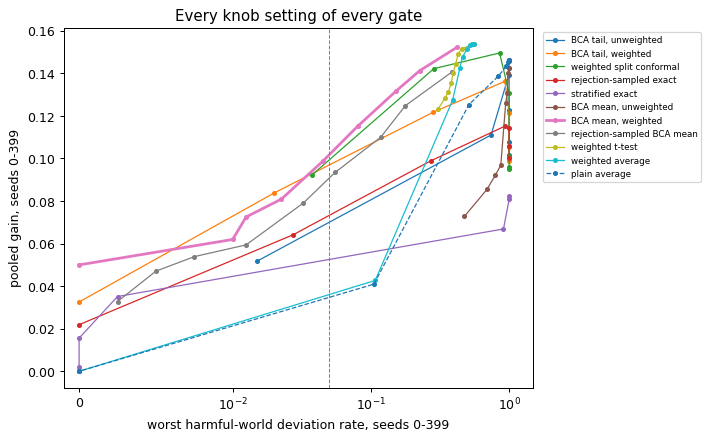

In [42]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, (g, points) in enumerate(FRONTIER.items()):
    ax.plot([p[1] for p in points], [p[2] for p in points], marker="o", ms=3,
            lw=2.2 if g == "BCA mean, weighted" else 1, color=f"C{i % 10}", ls="-" if i < 10 else "--", label=g)
ax.axvline(DELTA, color="grey", ls="--", lw=0.8)
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlim(-0.001, 1.5)
ax.set_xlabel("worst harmful-world deviation rate, seeds 0-399")
ax.set_ylabel("pooled gain, seeds 0-399")
ax.set_title("Every knob setting of every gate")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

print(f"{'gate':28}{'chosen knob':>12}{'gain, 0-399':>13}{'gain, 400-799':>15}{'worst harmful, 400-799':>24}")
for g, (k, tune_gain, eval_gain, eval_harm) in sorted(TUNED.items(), key=lambda kv: -kv[1][2]):
    print(f"{g:28}{'none' if k is None else str(k):>12}{tune_gain:13.4f}{eval_gain:15.4f}{eval_harm:24.3f}")

### Where the differences come from

The same measures, split by shift, by number of tries and by where harm sits, followed by the effective number of tries. The chart shows each gate's deviation rate along the rungs, under the strong shift with 120 tries. Rungs to the right of the first dashed line are unsafe, and to the right of the second are harmful.

In [43]:
key = TAIL_GATES + LEVEL_GATES + MARGIN_GATES
def by(fn, label, columns, fmt):
    print(label)
    print(f"{'gate':28}" + "".join(f"{c:>12}" for c in columns))
    for g in key:
        print(f"{g:28}" + "".join(f"{v:{fmt}}" for v in fn(rate(DEC[g]))))
    print()

by(lambda r: [r[:, :, s][UNSAFE_W[:, :, s]].max() for s in range(len(SHIFTS))],
   "Worst unsafe-world deviation rate, by shift", SHIFTS, "12.3f")
by(lambda r: [r[:, :, s][~UNSAFE_W[:, :, s]].mean() for s in range(len(SHIFTS))],
   "Deviation rate pooled over safe worlds, by shift", SHIFTS, "12.3f")
by(lambda r: [r[:, :, s][HARMFUL_W[:, :, s]].max() for s in range(len(SHIFTS))],
   "Worst harmful-world deviation rate, by shift", SHIFTS, "12.3f")
by(lambda r: [(r * GAIN_W)[:, :, s].mean() for s in range(len(SHIFTS))],
   "Pooled gain, by shift", SHIFTS, "12.4f")
by(lambda r: [r[..., z][SAFE_SHIFTED[..., z]].mean() for z in range(len(SIZES))],
   "Deviation rate pooled over safe shifted worlds, by number of tries", SIZES, "12.3f")
by(lambda r: [(r * GAIN_W)[..., z].mean() for z in range(len(SIZES))],
   "Pooled gain, by number of tries", SIZES, "12.4f")
by(lambda r: [(r * GAIN_W)[p, :, 2].mean() for p in range(len(PROFILES))],
   "Pooled gain under strong shift, by where harm sits", ("alike", "harsh", "mild"), "12.4f")

ess = R["wsum"] ** 2 / R["wsq"]
print("Effective number of tries, and tries kept by rejection sampling (averages over seeds)")
print(f"{'shift':10}" + "".join(f"{f'{n} tries':>18}" for n in SIZES))
for s, shift in enumerate(SHIFTS):
    print(f"{shift:10}" + "".join(f"{ess[:, 0, 0, s, z].mean():9.1f} /{R['kept'][:, 0, 0, s, z].mean():6.1f}  "
                                  for z in range(len(SIZES))))

Worst unsafe-world deviation rate, by shift
gate                                none    moderate      strong
BCA tail, unweighted               0.036       0.454       0.899
BCA tail, weighted                 0.031       0.043       0.037
weighted split conformal           0.388       0.369       0.355
rejection-sampled exact            0.036       0.026       0.025
stratified exact                   0.000       0.000       0.000
BCA mean, unweighted               0.119       0.746       0.986
BCA mean, weighted                 0.119       0.098       0.094
rejection-sampled BCA mean         0.119       0.079       0.044
weighted t-test                    0.179       0.240       0.440
weighted average                   0.730       0.714       0.689
plain average                      0.730       0.996       1.000

Deviation rate pooled over safe worlds, by shift
gate                                none    moderate      strong
BCA tail, unweighted               0.539       0.551       0.

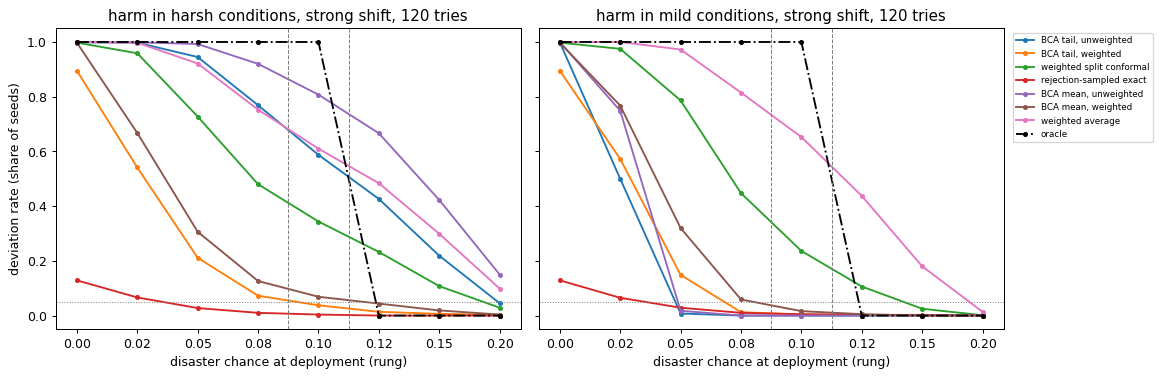

In [44]:
show = ["BCA tail, unweighted", "BCA tail, weighted", "weighted split conformal", "rejection-sampled exact",
        "BCA mean, unweighted", "BCA mean, weighted", "weighted average", "oracle"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, p in zip(axes, (1, 2)):
    for i, g in enumerate(show):
        ax.plot(range(len(RUNGS)), rate(DEC[g])[p, :, 2, SIZES.index(120)], marker="o", ms=3,
                color="k" if g == "oracle" else f"C{i}", ls="-." if g == "oracle" else "-", label=g)
    ax.axvline(int(np.argmax(UNSAFE)) - 0.5, color="grey", ls="--", lw=0.8)
    ax.axvline(int(np.argmax(HARMFUL)) - 0.5, color="grey", ls="--", lw=0.8)
    ax.axhline(DELTA, color="grey", ls=":", lw=0.8)
    ax.set_xticks(range(len(RUNGS))); ax.set_xticklabels([f"{r:.2f}" for r in RUNGS])
    ax.set_xlabel("disaster chance at deployment (rung)")
    ax.set_title(f"{PROFILES[p]}, strong shift, 120 tries")
axes[0].set_ylabel("deviation rate (share of seeds)")
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

**Checks.** These confirm that the toy works as described; any failure stops the notebook. Check 2 compares the weighted tail gate with production `calibration/wbcp.py` on 300 random cases, and skips itself if that file is missing.

In [45]:
# 1. Each world's disaster chances are valid and add up to its rung at deployment; the exact truths match simulation.
for pi in range(len(PROFILES)):
    for ri, rung in enumerate(RUNGS):
        for si, shift in enumerate(SHIFTS):
            pk = P_K[pi, ri, si]
            assert np.all((pk >= 0) & (pk <= 1)) and abs(DEPLOY_MIX[shift] @ pk - rung) < 1e-12
rng = np.random.default_rng([ROOT_SEED, 999])
cond = rng.choice(LOG_MIX.size, 1_000_000, p=DEPLOY_MIX["strong"])
gains = np.where(rng.random(cond.size) < P_K[1, 5, 2][cond], DISASTER,
                 np.clip(CENTER + SPREAD * rng.standard_normal(cond.size), LO, HI))
assert abs(gains.mean() - MU[5]) < 5 * gains.std() / 1000 and abs((gains < 0).mean() - BAD[5]) < 0.002
# 2. The weighted tail gate here decides exactly as production BCA (calibration/wbcp.py) does.
sys.dont_write_bytecode = True
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
try:
    from calibration.wbcp import calibrate
except ImportError:
    calibrate = None
    print("Check 2 skipped: run this notebook from the repository root to compare with calibration/wbcp.py.")
if calibrate is not None:
    rng = np.random.default_rng([ROOT_SEED, 997])
    for case in range(300):
        n, si = int(rng.choice(SIZES)), int(rng.integers(len(SHIFTS)))
        c = rng.choice(LOG_MIX.size, n, p=LOG_MIX)
        g_ = np.where(rng.random(n) < rng.uniform(0, 0.2), DISASTER, np.clip(CENTER + SPREAD * rng.standard_normal(n), LO, HI))
        w_, stream = WEIGHT[si, c], int(rng.integers(2 ** 32))
        production = calibrate(-g_, np.random.default_rng(stream), w_, float(WBAR[si]),
                               alpha=TAIL, beta=CONFIDENCE, draws=TAIL_DRAWS).threshold <= 0
        ex = np.random.default_rng(stream).standard_exponential((TAIL_DRAWS, n + 1))
        order = np.argsort(-g_, kind="stable")
        mass = ex[:, :n] * w_[order]
        s_good, s_all = (mass * (g_[order] >= 0)).sum(axis=1), mass.sum(axis=1)
        crossed = (s_good >= (1 - TAIL) * (s_all + ex[:, n] * WBAR[si])).sum()
        mine = bool(w_[g_ >= 0].sum() >= (1 - TAIL) * w_.sum() - 1e-9) and crossed >= NEED
        assert production == mine, case
# 3. The weighted mean gate's sampler matches the exact answer for identical tries: with gain g on every try, the
#    chance that the weighted average is below 0 is the product of 1 / (1 + g * w_i / (|floor| * WBAR)).
ex = np.random.default_rng([ROOT_SEED, 996]).standard_exponential((MEAN_DRAWS, N_MAX + 1))
for n, si, g_ in ((30, 1, 0.5), (120, 2, 0.3), (240, 2, 0.1)):
    w_ = WEIGHT[si, np.random.default_rng([ROOT_SEED, n]).choice(LOG_MIX.size, n, p=LOG_MIX)]
    estimate = ((ex[:, :n] * w_ * g_).sum(axis=1) + ex[:, N_MAX] * WBAR[si] * FLOOR < 0).mean()
    exact = np.prod(1 / (1 + g_ * w_ / (-FLOOR * WBAR[si])))
    assert abs(estimate - exact) < 4 * math.sqrt(exact * (1 - exact) / MEAN_DRAWS) + 1e-4, (n, si, estimate, exact)
# 4. Clopper-Pearson bounds match the closed form with no bad tries, and sit exactly at their level otherwise.
for n in (1, 5, 29, 100, 240):
    assert abs(cp_upper([0], [n], STRATA_LEVEL)[0] - (1 - STRATA_LEVEL ** (1 / n))) < 1e-9
for b, n in ((1, 10), (3, 50), (20, 240)):
    p = cp_upper([b], [n], STRATA_LEVEL)[0]
    assert abs(sum(math.comb(n, x) * p ** x * (1 - p) ** (n - x) for x in range(b + 1)) - STRATA_LEVEL) < 1e-9
# 5. Student's t quantiles match published tables, and BCA's exact tail gate cannot say yes below 29 tries.
for level, df, want in ((0.05, 29, 1.6991), (0.05, 9, 1.8331), (0.01, 29, 2.4620)):
    assert abs(t_upper(level, df) - want) < 1e-3, (level, df)
assert allowed_below(28, TAIL) == -1 and allowed_below(29, TAIL) == 0
# 6. Rejection sampling keeps tries in deployment's mix.
rng = np.random.default_rng([ROOT_SEED, 995])
cond = rng.choice(LOG_MIX.size, 2_000_000, p=LOG_MIX)
for si, shift in enumerate(SHIFTS):
    kept = cond[rng.random(cond.size) < WEIGHT[si, cond] / WMAX[si]]
    assert np.allclose(np.bincount(kept, minlength=LOG_MIX.size) / kept.size, DEPLOY_MIX[shift], atol=0.003), shift
# 7. With no shift, every weight is 1, so each weighted gate reduces to its unweighted twin.
assert WBAR[0] == 1.0 and np.all(WEIGHT[0] == 1.0)
assert np.array_equal(R["neg_w"][..., 0, :], R["neg_u"][..., 0, :])
assert np.array_equal(R["neg_r"][..., 0, :], R["neg_u"][..., 0, :])
assert np.array_equal(DEC["rejection-sampled exact"][..., 0, :], DEC["BCA tail, unweighted"][..., 0, :])
assert np.allclose(R["m_w"][..., 0, :], R["m_u"][..., 0, :])
same = (DEC["BCA tail, weighted"][..., 0, :] == DEC["BCA tail, unweighted"][..., 0, :]).mean()
print(f"With no shift, BCA's sampled tail gate (1,000 draws) and its exact form agree in {same:.2%} of cases.")
print("All checks passed. Notebook seconds:", round(time.perf_counter() - START, 1))

With no shift, BCA's sampled tail gate (1,000 draws) and its exact form agree in 98.51% of cases.
All checks passed. Notebook seconds: 168.7


## What Part 4 found

| Claim | Result | Verdict |
|---|---|---|
| 1. Ignoring the shift breaks the tail promise | up to 89.9% unsafe deviations; 17 unsafe worlds above the allowance | alive |
| 2. With weights, the tail gate as built keeps its promise | at most 4.3% in any unsafe world | alive |
| 3. Weights use shifted evidence better than the simple valid alternatives | said yes in 33.6% of seeds in safe shifted worlds, against 19.0% (rejection sampling) and 0% (stratified) | alive |
| 4. Weighted BCA's promise holds for the data in hand; weighted split conformal's does not | worst unsafe-world rate 4.3%, against 38.8% | alive |
| 5. With weights, the mean gate keeps its promise | at most 4.4% in any harmful world | alive |
| 6. At equal harm, the weighted mean gate earns the most | 0.0975 per decision, against 0.0923 for a tuned weighted split conformal | alive, narrowly |

- **Ignoring the shift breaks both promises.** Unweighted gates answer for the log's mix of conditions, and there the deviation looked safe. When harm sits in conditions deployment meets more often, the unweighted tail gate deviated in up to 90% of seeds in an unsafe world. The unweighted mean gate deviated in up to 94% of seeds in a harmful world.
- **With weights, both BCA gates kept their promise in every world.** Check 2 confirms that the weighted tail gate decides exactly as production `calibration/wbcp.py` does. No proof covers the weighted mean gate, and no world broke it here. It does deviate in the unsafe-but-good rung 0.10, as a mean gate should.
- **The weights keep more evidence than the simple valid alternatives.** Under the strong shift, 120 tries counted as about 42 equally weighted ones to BCA, while rejection sampling kept only about 24. Per-condition exact bounds need about 287 or 382 tries under the two shifts before they can say yes, and no world has more than 240.
- **Weighted split conformal failed for the data in hand,** as split conformal did without weights in Part 2. Its promise holds only on average over data sets.
- **At equal harm, the weighted mean gate led, narrowly.** It led on both halves of the seeds: 0.0988 against 0.0923 on the tuning half. Next came weighted split conformal tuned to a 5% share (0.0923), the weighted tail gate (0.0838) and the rejection-sampled mean gate (0.0788). The unweighted mean gate, the weighted t-test and the two averages had no useful safe setting. The tuned mean gate's worst harmful-world rate on the fresh seeds was 5.2%, within sampling noise of 5%.
- **The price is evidence.** Under the strong shift, the weighted tail gate could not say yes with fewer than about 83 tries, against 29 with no shift. Ignoring the shift earned more return (0.111 against 0.084), but only by breaking the promise in 17 unsafe worlds. Held to the same safety level, the unweighted tail gate earned less (0.054).

### Information only: a weighted mean gate that a proof covers (added after the first run)

This is not one of the claims and has no kill rule. It was added after seeing the results.

The research report recommended a different weighted mean gate from the one tested above. It reweights each outcome (its weight times its gain), then runs the ordinary mean gate with equal random shares. The July 2026 proof appears to cover that version when the weights are known.

The two versions differ in one number. Both add up the same reweighted outcomes with the same random shares. They differ in the extra worst-case try that stands in for the unseen deployment outcome:
- **BCA's weighted mean gate, as tested above,** gives the worst case the average weight at deployment: 1.37 under the moderate shift and 2.91 under the strong one.
- **The version a proof covers** gives it the largest weight, 2.5 and 5, because a reweighted outcome can be that bad.

So the version tested above is the more optimistic of the two. The cell below replays the same seeds with the worst case at the largest weight. It first checks that the replay reproduces the stored results of the version above exactly.

In [46]:
def worst_case_counts(seed):
    """Replays run_seed's draws; counts negative weighted averages with the worst case at the average and largest weight."""
    rng = np.random.default_rng([ROOT_SEED, STREAM, seed])
    cond = rng.choice(LOG_MIX.size, N_MAX, p=LOG_MIX)
    u, v = rng.random((2, N_MAX))
    z = rng.standard_normal(N_MAX)
    e = rng.standard_exponential((MEAN_DRAWS, N_MAX + 1))
    gain = np.where(u < P_K[..., cond], DISASTER, np.clip(CENTER + SPREAD * z, LO, HI))
    w = WEIGHT[:, cond]
    average, largest = np.zeros(WORLD), np.zeros(WORLD)
    for zi, n in enumerate(SIZES):
        g = gain[..., :n]
        x = np.broadcast_to(w[None, None, :, :n] * g, g.shape).reshape(-1, n).T
        for out, weight in ((average, WBAR), (largest, WMAX)):
            sums = e[:, :n] @ x + e[:, N_MAX][:, None] * (weight[SHIFT_OF] * FLOOR)[None, :]
            out[..., zi] = (sums < 0).sum(axis=0).reshape(WORLD[:3])
    return average, largest

replayed = [worst_case_counts(s) for s in range(N_SEEDS)]
assert np.array_equal(np.stack([r[0] for r in replayed]), R["neg_w"])
NEG_LARGEST = np.stack([r[1] for r in replayed])

VERSIONS = {"BCA mean, weighted": lambda k: accept("BCA mean, weighted", k),
            "BCA mean, largest weight": lambda k: NEG_LARGEST <= limit(k)}
print(f"{'version':26}{'worst harmful':>14}{'safe, shifted':>15}{'gain':>8}"
      f"{'tuned level':>13}{'tuned gain':>12}{'tuned worst harmful':>21}")
for name, decide in VERSIONS.items():
    r = rate(decide(DELTA))
    points = [(k, rate(decide(k), TUNE_SEEDS)[HARMFUL_W].max(), pooled_gain(decide(k), TUNE_SEEDS), decide(k))
              for k in LEVELS]
    qualified = [p for p in points if p[1] <= DELTA]
    k, _, _, d = max(qualified, key=lambda p: p[2]) if qualified else (None, 0, 0, np.zeros((N_SEEDS,) + WORLD, bool))
    print(f"{name:26}{r[HARMFUL_W].max():14.3f}{r[SAFE_SHIFTED].mean():15.3f}{pooled_gain(decide(DELTA)):8.4f}"
          f"{str(k):>13}{pooled_gain(d, EVAL_SEEDS):12.4f}{rate(d, EVAL_SEEDS)[HARMFUL_W].max():21.3f}")
print(f"Best tuned rival in claim 6, {best_rival}: tuned gain {TUNED[best_rival][2]:.4f}")
print("Tuned gains are on seeds 400-799, after tuning on seeds 0-399 as in claim 6.")
print("\nPooled gain at the stated 5% level, by shift")
print(f"{'version':26}" + "".join(f"{s:>10}" for s in SHIFTS))
for name, decide in VERSIONS.items():
    by = rate(decide(DELTA)) * GAIN_W
    print(f"{name:26}" + "".join(f"{by[:, :, si].mean():10.4f}" for si in range(len(SHIFTS))))

version                    worst harmful  safe, shifted    gain  tuned level  tuned gain  tuned worst harmful
BCA mean, weighted                 0.044          0.415  0.0982         0.05      0.0975                0.052
BCA mean, largest weight           0.026          0.273  0.0804          0.1      0.0954                0.055
Best tuned rival in claim 6, weighted split conformal: tuned gain 0.0923
Tuned gains are on seeds 400-799, after tuning on seeds 0-399 as in claim 6.

Pooled gain at the stated 5% level, by shift
version                         none  moderate    strong
BCA mean, weighted            0.1288    0.1019    0.0637
BCA mean, largest weight      0.1288    0.0739    0.0383


**What it showed (information only).** The replay matched the stored results exactly, so both versions saw the same draws.
- **At the stated 5% level, the version a proof covers is more cautious.** Its worst harmful-world rate was 2.6%, against 4.4% for the version above. It said yes in 27% of safe shifted cases, against 42%. It earned 0.080 per decision, against 0.098. The whole gap is in the shifted worlds: under the strong shift, 0.038 against 0.064. With no shift, the two versions are the same.
- **At equal harm, the gap nearly closes.** Tuned as in claim 6, the proof-covered version ran at a 10% level and earned 0.0954 on seeds 400–799, against 0.0975. Both beat the best tuned rival from claim 6, weighted split conformal at 0.0923. Its worst harmful-world rate on those seeds was 5.5%, within sampling noise of 5%.
- **The trade-off.** The version tested above earned about a fifth more at the stated level, but only this toy supports its promise. The proof-covered version earns less at the stated level because its promise is looser than needed here. Its safety rests on a proof, though one not yet peer reviewed. Tuning it to a looser stated level recovered nearly all the return, but that tuning used worlds whose truth is known.

**The insight.** Under a shift in the mix of states, BCA's weights are what make a valid gate possible: ignoring the shift broke both promises in the worst worlds. The weights use the evidence better than discarding it, but a shift still costs evidence. For a weighted mean gate, give the worst case the largest weight: a proof appears to cover that version, and it gives up little at equal harm.

---
# What it all adds up to

## Every pre-registered claim at a glance

| Part | Claim | Verdict | Key number |
|---|---|---|---|
| 2 | BCA's width at every action removes at least a quarter of the room | shelved | −2.50 and −2.09 of the room |
| 2 | The step-1 gate removes at least half the room, from the outcomes themselves | alive | +0.58; shuffled outcomes keep none |
| 2 | Comparing with the safe action's value beats a margin against the rest | alive | regret 0.028 against 0.051 |
| 2 | BCA decides differently from the exact binomial test | shelved | 99.6% agreement |
| 2 | BCA's confidence makes deviations safer than split conformal | alive, narrowly | 5.5 points safer, against a 5-point bar |
| 2 | Safety needs a quantile, not an average | alive | 28.8 points safer |
| 3 | The mean gate keeps its promise | alive | worst harm 0.3% |
| 3 | It is the tightest guaranteed mean gate | alive | 17.4% of good accepted, against 0% |
| 3 | The t-test is unsafe with rare disasters | alive | up to 31.3% harm |
| 3 | In crowded worlds it beats simple averaging | shelved | 0.057 against 0.183 and 0.163 |
| 3 | At equal harm it earns the most | alive | 0.084 against 0.040 |
| 3 | Deciding all situations together earns more | shelved | 0.027 against 0.045 |
| 4 | Ignoring the shift breaks the tail promise | alive | up to 89.9% unsafe deviations |
| 4 | With weights, the tail gate as built keeps its promise | alive | at most 4.3% |
| 4 | Weights use shifted evidence better than the simple valid alternatives | alive | 33.6% against 19.0% and 0% |
| 4 | Weighted BCA's promise holds for the data in hand, unlike weighted split conformal's | alive | 4.3% against 38.8% |
| 4 | With weights, the mean gate keeps its promise | alive | at most 4.4% |
| 4 | At equal harm, the weighted mean gate earns the most | alive, narrowly | 0.0975 against 0.0923 |

Fourteen of the eighteen claims survived. The four shelved ones say the most:
- BCA's width does not help as built.
- With equal weights, BCA adds no information over a textbook test.
- Caution does not raise return when the held-out evidence is already honest.
- A shared harm budget does not help when few actions pass at all.

## What this means for BCA

1. **Use BCA as a certificate on deviations, not as a width in training.** A width calibrated at logged actions cannot see the actions the log lacks, and its caution costs return (Parts 1 and 2). This agrees with ThrusterChain's earlier results. The width doses (the behavior-cloning multiplier in TD3+BC and ReBRAC, and the conservative-penalty multiplier in CQL) are the wrong vehicle for BCA claims.
2. **Measure a deviation against the fallback's value.** Deviate only if a bound on the deviation's held-out outcomes beats the fallback action's value, which the critic estimates on data. In Part 2 this cut the step-1 gate's regret from 0.051 to 0.028, and it drops the gate's free 0.10 margin.
3. **Match the gate to the promise you need.**
   - **Return at a fixed safety level:** BCA's mean gate. At equal harm, it earned 0.084 against 0.040 and 0.019 in Part 3, and the most in Part 4 too.
   - **Rarely worse than the fallback:** BCA's tail gate. It kept unsafe deviations at or below 3% in Part 2, against up to 38% for split conformal.
   - **No safety requirement:** the plain held-out average earns the most (Part 2 regret 0.016; Part 3 gain 0.158).
4. **Use weights when the held-out tries come from a different mix of states than deployment.** They kept both promises in Part 4, where ignoring the shift broke them. For the mean gate, use the version with the largest weight on the worst case.
5. **Compute equal-weight BCA exactly.** With equal weights, the tail gate is the exact binomial test. With 1,000 random draws, only 4 of 8 score sets matched the exact answer at 28 and 29 tries (Part 2). Exact arithmetic also lowers the evidence floor from 36 rows (production's allowance for sampling error) to 29. Keep the random draws for weighted banks.
6. **Describe it plainly.** With equal weights, BCA's tail gate is a textbook tolerance limit (Wilks), and its mean gate is Gaffke's bound computed with BCA's sampler. The defensible claims are a per-decision safety certificate and the most return at a fixed safety level. The claim that BCA's Bayesian posterior adds information is not supported.
7. **Budget the evidence.** The tail gate needs at least 29 held-out outcomes per decision with no shift, about 39 under the moderate shift and about 83 under the strong one. Step 1's ThrusterChain gate had only 28–59 outcomes per seed and world.

## What this does not show

- Everything ran on toy seeds. Nothing here is ThrusterChain or host evidence, and nothing is confirmatory.
- Every gate read real, independent held-out tries of the deviation, and the deviation was given. A real gate must find its deviations and group similar ones, and each split of the evidence costs tries.
- The floors and weights were known exactly. A wrong floor voids the mean gate's promise, and estimated weights are untested.
- Each decision stood alone. None of the worlds lets a critic's errors spread backwards through its own targets, the main failure mode in offline reinforcement learning.
- The mean gate's guarantee rests on an unreviewed 2026 preprint. BCA's own weighted mean gate, with the average weight on the worst case, has no proof.

## Next steps

1. **Estimated weights.** This test is designed but not yet run. Estimate deployment's mix from a small sample of deployment states (10 to 300). Then compare plug-in weights with BCA drawing a fresh plausible mix inside each of its random draws. As before, the kill rules would be fingerprinted before the first run.
2. **A ThrusterChain test of the mean gate at deviations.** This changes step 2 and needs a new pre-registration, approved at your terminal.
3. **Exact equal-weight BCA in production.** This is a small change to `calibration/wbcp.py` and needs your approval.

## Where these results came from

| Part | Original notebook | Kill rules fingerprint | Running time here |
|---|---|---|---|
| 1 | `bca_discrete_toy.ipynb` | none (exploratory) | about a second |
| 2 | `bca_channel_toy.ipynb` | `bb9e0325…dbc3` | under a minute |
| 3 | `bca_mean_gate_toy.ipynb` | `50a0f49d…b1d3` | under half a minute |
| 4 | `bca_weights_toy.ipynb` | `e32e04d7…f44e` | three to five minutes |

- Each part's code is copied unchanged from its original notebook, and every result those notebooks printed is reproduced here exactly. Only the explanations are new.
- The literature behind Parts 3 and 4 is reviewed in `reports/Calibrated bounds in policy optimization.md`.
- BCA follows Weighted Bayesian Conformal Prediction ([Lou and Luo](https://arxiv.org/abs/2604.06464v3), Algorithm 1).